# Do Active Mutual Fund Fees Survive Better Benchmarks?
**CFM301 Project 5: five active growth mutual funds, January 2016–December 2025**

**Research question:** Does an active mutual fund's fee remain justified when performance is evaluated against progressively more demanding benchmarks?

**Audience:** Retail investors and financial advisors evaluating the value of active US growth management. These are historical case studies, including funds closed to some new investors, rather than a list of funds everyone can buy today.

Run all cells from this folder. All inputs are included in `data/`; no internet, paid subscription, WRDS login or manual data entry is needed. Tables and figures display inline and are saved to `output/`. One share class per active fund is used throughout the main performance analysis.

| Section | Content | Assignment requirement |
|---|---|---|
| 1 | Economic motivation, hypotheses, sample and decision rule | 1–2 |
| 2–3 | Local sources, return construction, fees and one cleaning log | 2–4 |
| 4 | Descriptive statistics and validation against published total returns | 3–4 |
| 5 | CAPM, FF3 and Carhart: alpha, t-statistic, residual TE, appraisal ratio, R² | 5 |
| 6 | Gross/net alpha and the amount left for the investor | 6 |
| 7 | Non-negative, fully invested index-fund benchmarks; cost and fit | 7 |
| 8 | Fees, turnover and ICI's equity/growth fee distributions | 8 |
| 9 | Half-sample persistence and flows; Berk and Green | 9 |
| 10 | Different sample, winsorization, fee timing, benchmark set, rolling estimates | 10 |
| 11 | Fund-by-fund verdict, research answer, fee design and limitations | 11–12 |
| 12 | Consistency checks, sources and submission checklist | All |

**Data limitation affecting requirement 9.** A complete monthly **share-class** TNA history could not be established from the free sources. We implement the requested monthly formula on genuinely consecutive monthly TNA observations (none available), calculate the same formula at the observed annual class frequency for all five funds, and separately analyze actual reported monthly **series-level** flows for the two T. Rowe Price funds. These are explicitly different datasets. No annual/quarterly assets are interpolated into monthly observations. The professor's supplied clarification permits documenting such limitations; it does not make the original monthly-TNA requirement fully satisfied.

## 1. Economic motivation and research design

A strong return can reflect market risk, growth exposure or momentum rather than manager value added. Paying an active fee makes sense under the assignment's definition only when estimated gross alpha covers the expense ratio and leaves non-negative net alpha. We ask whether that conclusion survives CAPM, FF3, Carhart and a cheap, investable style benchmark.

**Predictions, which the evidence can reject:** (1) some apparent CAPM alpha reflects style exposures, (2) positive gross alpha need not leave positive net alpha, (3) a low-cost index portfolio can explain much of a growth fund's performance, and (4) a fee verdict may change across benchmarks or periods. More factors do **not** mechanically lower estimated alpha, so we do not impose a monotonic pattern.

**Sample fixed before estimating alphas:** FBGRX (Fidelity Blue Chip Growth), FDGRX (Fidelity Growth Company), FOCPX (Fidelity OTC), PRGFX (T. Rowe Price Growth Stock), TRBCX (T. Rowe Price Blue Chip Growth). These are five long-lived, actively managed growth-oriented equity funds with usable public histories and financial highlights. Their mandates are similar rather than identical: technology, foreign and smaller-company holdings vary. Three are Fidelity funds and two are T. Rowe Price funds, so this is a small, concentrated convenience sample. It cannot estimate the causal effect of fees or represent all US active funds. The availability rule conditions on survival and good public records.

**Main period:** January 2016–December 2025 (120 months). Returns from 2015 supply lagged one-year predictors. One retail/Investor share class per fund avoids treating several classes of one portfolio as independent managers. Annual assets and expense ratios refer to that same class. Benchmark classes are Vanguard Admiral mutual funds: VFIAX (S&P 500), VIGAX (growth), VVIAX (value), VSMAX (small cap). Growth is included so a convex portfolio can represent a growth mandate. The index-fund allocation is hypothetical and ignores minimum investment constraints, taxes and external advisory charges.

**Decision rule:** net alpha ≥ 0 means the fee *appears justified by the point estimate* under that benchmark. Separately report a 95% confidence interval and whether evidence supports positive alpha, negative alpha, or remains inconclusive. A failure to reject zero is not proof of non-negative alpha or skill. Carhart is the principal factor verdict; the long-only index comparison answers what an investor could buy instead. All factor models use identical dates. Six monthly HAC lags are specified before estimation, with finite-sample correction and Student-t inference. Benjamini–Hochberg q-values across the five main Carhart tests supplement, rather than replace, the unadjusted confidence intervals.

## 2. Imports and local source files

The organization follows Projects 2–4: numbered Markdown sections, short pandas calculations, an explanation after each code cell, inline tables and matplotlib figures, economic interpretation, sensitivity, and a reproducibility checklist.

| File in `data/` | Source / raw units | Use |
|---|---|---|
| `funds.csv` | SEC class/series identifiers and documented selection | Prevent share-class/portfolio mismatches |
| `yahoo_daily.csv`, `yahoo_actions.csv` | Yahoo daily split-adjusted NAV, adjusted close, cash distributions and split-event metadata | Construct monthly total returns; compare adjusted-close method |
| `financial_highlights_raw.csv` | Published financial-highlight rows; expense/return/turnover strings in percent, assets with original unit multiplier | Annual fees, returns and class assets |
| `financial_highlights_sources.json` | Exact selected table text/rows, headings, filing dates and source URLs | Audit extraction and fund/class identity |
| `factors_percent.csv` | Ken French monthly US FF3 + momentum; percentage units | Excess-return regressions |
| `ici_fee_distribution.csv` | ICI Figure 2, 2025, percentage units | Equity and growth fee-distribution bands |
| `sec_reported_monthly_flows.csv` | N-PORT reported series sales, redemptions, reinvestments, USD | Actual monthly flows for PRGFX/TRBCX series |
| `sec_quarterly_series_assets.csv` | N-PORT quarter-end series TNA, USD | Scale reported flows without inventing monthly assets |
| `sec_monthly_class_returns.csv` | N-PORT monthly class returns, percent | Independently validate the two retail return series |
| `sources.json` | Source definitions, acquisition date and SHA256 checksums | Fixed vintage and integrity checks |

The submitted CSVs are source extracts restricted to the actual funds, fields and periods used. Downloaded full fund-family filings are excluded. Factor files use the same September 2026 vintage, downloaded November 20, 2026; the notebook never refreshes them.

In [1]:
from pathlib import Path
import calendar, hashlib, importlib.metadata as metadata, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from scipy.optimize import minimize
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

%matplotlib inline
DATA, OUT = Path('data'), Path('output')
OUT.mkdir(exist_ok=True)
START, END = pd.Period('2016-01', 'M'), pd.Period('2025-12', 'M')
MONTHS = pd.period_range(START, END, freq='M')
ACTIVE = ['FBGRX', 'FDGRX', 'FOCPX', 'PRGFX', 'TRBCX']
INDEX = ['VFIAX', 'VIGAX', 'VVIAX', 'VSMAX']
ALL = ACTIVE + INDEX
HAC_LAGS = 6
MODELS = {'CAPM': ['Mkt_RF'], 'FF3': ['Mkt_RF', 'SMB', 'HML'],
          'Carhart': ['Mkt_RF', 'SMB', 'HML', 'Mom']}
HALVES = {'2016–2020': ('2016-01', '2020-12'), '2021–2025': ('2021-01', '2025-12')}
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 75)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .20, 'savefig.dpi': 150})
cleaning_log = []
def log(dataset, step, affected, remaining, note=''):
    cleaning_log.append(dict(dataset=dataset, step=step, affected=int(affected),
                             remaining=int(remaining), note=note))
def save_table(frame, name, show=True):
    frame = frame.copy()
    if frame.index.nlevels == 1 and frame.index.name is None:
        frame.index = frame.index.rename('ticker' if frame.index.isin(ALL).all() else
            'month' if isinstance(frame.index, pd.PeriodIndex) else 'row')
    frame.to_csv(OUT / f'{name}.csv', index=True)
    if show: display(frame)
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight')
    plt.show()

versions = pd.Series({p: metadata.version(p) for p in
    ['numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']}, name='Version')
print('Python:', sys.version.split()[0])
display(versions.to_frame())
sources = json.loads((DATA / 'sources.json').read_text())
funds = pd.read_csv(DATA / 'funds.csv').set_index('ticker').loc[ALL]
raw_daily = pd.read_csv(DATA / 'yahoo_daily.csv')
raw_actions = pd.read_csv(DATA / 'yahoo_actions.csv')
raw_highlights = pd.read_csv(DATA / 'financial_highlights_raw.csv', keep_default_na=False)
raw_factors = pd.read_csv(DATA / 'factors_percent.csv', dtype={'month': str})
display(funds[['name', 'role', 'share_class', 'series_id', 'class_id']],
        raw_daily.head(), raw_actions.head(), raw_highlights.head())

Python: 3.11.4


,Version
numpy,2.4.6
pandas,3.1.1
scipy,1.17.1
statsmodels,0.15.0
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


,name,role,share_class,series_id,class_id
ticker,,,,,
FBGRX,Fidelity Blue Chip Growth Fund,active,retail / Investor,S000007195,C000019693
FDGRX,Fidelity Growth Company Fund,active,retail / Investor,S000007119,C000019448
FOCPX,Fidelity OTC Portfolio,active,retail / Investor,S000007191,C000019679
PRGFX,T. Rowe Price Growth Stock Fund,active,retail / Investor,S000002087,C000005453
TRBCX,T. Rowe Price Blue Chip Growth Fund,active,retail / Investor,S000002069,C000005424
VFIAX,Vanguard 500 Index Fund Admiral Shares,index,Admiral,S000002839,C000007774
VIGAX,Vanguard Growth Index Fund Admiral Shares,index,Admiral,S000002842,C000007784
VVIAX,Vanguard Value Index Fund Admiral Shares,index,Admiral,S000002840,C000007776
VSMAX,Vanguard Small-Cap Index Fund Admiral Shares,index,Admiral,S000002845,C000007796


,ticker,date,nav,adj_close
0,FBGRX,2014-12-31,68.4200,39.3990
1,FBGRX,2015-01-02,68.3200,39.3414
2,FBGRX,2015-01-05,67.1500,38.6677
3,FBGRX,2015-01-06,66.3800,38.2243
4,FBGRX,2015-01-07,67.4400,38.8347


,ticker,date,event,amount,numerator,denominator
0,FBGRX,2015-09-11,dividends,3.4700,NaN,NaN
1,FBGRX,2015-12-11,dividends,0.1870,NaN,NaN
2,FBGRX,2016-09-16,dividends,0.9630,NaN,NaN
3,FBGRX,2016-12-09,dividends,1.7630,NaN,NaN
4,FBGRX,2017-09-15,dividends,1.7360,NaN,NaN


,ticker,fiscal_year,fiscal_month,expense_raw,turnover_raw,reported_return_raw,assets_raw,assets_multiplier,source_id,filing_date
0,FDGRX,2025,11,.69%,16 %,23.90 %,"71,629,186","1,000.0000",FDGRX_000070782326000019_table490,2026-01-22
1,FDGRX,2024,11,.52%,18%,44.23%,"60,512,551","1,000.0000",FDGRX_000070782326000019_table490,2026-01-22
2,FDGRX,2023,11,.71%,12%,26.74%,"43,116,057","1,000.0000",FDGRX_000070782326000019_table490,2026-01-22
3,FDGRX,2022,11,.86%,14%,(29.90)%,"34,900,124","1,000.0000",FDGRX_000070782326000019_table490,2026-01-22
4,FDGRX,2021,11,.79%,16%,31.76%,"53,845,109","1,000.0000",FDGRX_000070782326000019_table490,2026-01-22


**What this does:** loads only included relative-path inputs, declares the sample and inference choices once, and displays source fields before transforming them.

## 3. Cleaning, returns, expenses and calendar alignment
### 3.1 Daily NAVs and distributions

For these Yahoo responses, `nav` (the Yahoo `close` field) and historical cash distributions are already on a split-adjusted share basis. FDGRX and FOCPX have 10-for-1 split events in 2018; applying the split ratio again would create a false return. Split metadata are audited but are not multiplied into prices or distributions.

For each trading day, with distributions reinvested at that day's NAV,
\[
r_{i,d}^{net}=\frac{NAV_{i,d}+D_{i,d}}{NAV_{i,d-1}}-1,
\qquad r_{i,t}^{net}=\prod_{d\in t}(1+r_{i,d}^{net})-1.
\]
Yahoo's distribution event buckets can include both income and capital gains. We sum each returned cash event once, without assuming that the `dividends` bucket means income only. Adjusted close is retained as an alternative, not combined with cash distributions. Published total returns and SEC returns check whether the reconstruction works. Returns are before investor taxes and external account/advisory charges, after the fund's operating expenses. No extra fee is subtracted to obtain net returns.

In [2]:
daily = raw_daily.copy()
daily['date'] = pd.to_datetime(daily.date, errors='coerce')
for col in ['nav', 'adj_close']:
    daily[col] = pd.to_numeric(daily[col], errors='coerce')
n = len(daily)
daily = daily.drop_duplicates()
log('daily NAV', 'Drop exact duplicate source rows', n-len(daily), len(daily))
assert not daily.duplicated(['ticker', 'date']).any(), 'Conflicting ticker/date records'
bad = daily.date.isna() | daily.nav.isna() | (daily.nav <= 0)
log('daily NAV', 'Invalid dates, missing/non-positive NAV', bad.sum(), len(daily)-bad.sum())
assert not bad.any(), 'Inspect invalid daily records before proceeding; do not bridge them'
daily = daily.sort_values(['ticker', 'date']).reset_index(drop=True)
actions = raw_actions.copy()
actions['date'] = pd.to_datetime(actions.date, errors='coerce')
assert actions.date.notna().all()
n = len(actions); actions = actions.drop_duplicates()
log('actions', 'Drop exact duplicate event rows', n-len(actions), len(actions))
assert not actions.duplicated(['ticker', 'date', 'event']).any(), 'Conflicting cash events'
cash = actions.loc[actions.event.isin(['dividends', 'capitalGains'])].copy()
cash['amount'] = pd.to_numeric(cash.amount, errors='coerce')
assert cash.amount.notna().all() and (cash.amount >= 0).all()
cash = cash.groupby(['ticker', 'date'], as_index=False).amount.sum().rename(columns={'amount': 'distribution'})
daily = daily.merge(cash, on=['ticker', 'date'], how='left', validate='one_to_one')
assert len(daily.merge(cash, on=['ticker', 'date'], how='inner')) == len(cash)
daily['distribution'] = daily.distribution.fillna(0.)  # No event means zero, not a missing NAV.
previous_nav = daily.groupby('ticker').nav.shift()
daily['net_return'] = (daily.nav + daily.distribution) / previous_nav - 1
daily['adjusted_return'] = daily.adj_close / daily.groupby('ticker').adj_close.shift() - 1
log('daily NAV', 'First observation has no prior NAV', daily.net_return.isna().sum(),
    daily.net_return.notna().sum(), 'One initial observation per fund; all analysis months have a prior NAV')
assert daily.net_return.isna().sum() == len(ALL)
reference_dates = daily.loc[daily.ticker.eq('VFIAX'),'date'].to_numpy()
assert all(np.array_equal(daily.loc[daily.ticker.eq(t),'date'].to_numpy(),reference_dates) for t in ALL), 'Daily coverage differs across US fund classes; inspect trading-date gaps'
assert (daily.net_return.dropna() > -1).all()
daily['month'] = daily.date.dt.to_period('M')
monthly_long = daily.groupby(['month', 'ticker']).agg(
    net_return=('net_return', lambda x: np.prod(1+x.dropna())-1),
    adjusted_return=('adjusted_return', lambda x: np.prod(1+x.dropna())-1),
    trading_days=('net_return', 'count'))
net_full = monthly_long.net_return.unstack('ticker').reindex(columns=ALL).loc['2015-01':'2025-12']
adjusted_full = monthly_long.adjusted_return.unstack('ticker').reindex(columns=ALL).loc[net_full.index]
expected = pd.period_range('2015-01', '2025-12', freq='M')
assert net_full.index.equals(expected) and net_full.notna().all().all()
coverage = daily.groupby('ticker').agg(first_date=('date','min'), last_date=('date','max'), daily_rows=('date','size'))
coverage['analysis_months'] = net_full.loc[MONTHS].notna().sum()
save_table(coverage.loc[ALL], 'table_source_coverage')
display(actions.loc[actions.event.eq('splits'), ['ticker', 'date', 'numerator', 'denominator']])

,first_date,last_date,daily_rows,analysis_months
ticker,,,,
FBGRX,2014-12-31,2025-12-31,2767,120
FDGRX,2014-12-31,2025-12-31,2767,120
FOCPX,2014-12-31,2025-12-31,2767,120
PRGFX,2014-12-31,2025-12-31,2767,120
TRBCX,2014-12-31,2025-12-31,2767,120
VFIAX,2014-12-31,2025-12-31,2767,120
VIGAX,2014-12-31,2025-12-31,2767,120
VVIAX,2014-12-31,2025-12-31,2767,120
VSMAX,2014-12-31,2025-12-31,2767,120


,ticker,date,numerator,denominator
33,FDGRX,2018-08-10,10.0000,1.0000
53,FOCPX,2018-05-11,10.0000,1.0000


**What this does:** checks uniqueness and dates, reconstructs total returns from NAVs and distributions, verifies event alignment, and keeps a complete monthly calendar without filling missing prices.

### 3.2 Financial highlights and historical expense ratios

Financial highlights report the expense actually incurred **net of all reductions/waivers**, rather than the contractual headline fee. Preserve the original percent strings and asset-unit multipliers, parse them explicitly, and resolve repeated fiscal years by using the most recently filed table. The old and new tables overlap; they are repeated descriptions of the same fiscal year, not additional observations.

The fiscal expense ratio is an annual average. Allocate it evenly to the months of that fiscal year and divide by 12. This is an ex-post expense add-back approximation, not a point-in-time forecast or a recovery of transaction costs. A fiscal year that ends in 2026 may cover late-2025 months and is retained when available in this November 2026 data vintage. FDGRX's fiscal year ending November 2026 is not yet complete: only December 2025 requires the last observed fiscal expense as a one-month approximation. We flag that month, show the affected count, and test fee timing and exclusion of that approximation later.

In [3]:
def parse_percent(value):
    s = str(value).strip().replace('%', '').replace(' ', '').replace('–', '-').replace('−', '-')
    if not s: return np.nan
    if s.startswith('(') and s.endswith(')'): s = '-' + s[1:-1]
    return float(s) / 100

highlights = raw_highlights.copy()
for raw, clean in [('expense_raw', 'expense'), ('turnover_raw', 'turnover'),
                   ('reported_return_raw', 'reported_return')]:
    highlights[clean] = highlights[raw].map(parse_percent)
highlights['net_assets'] = pd.to_numeric(highlights.assets_raw.str.replace(',', ''), errors='coerce') * highlights.assets_multiplier
highlights['fiscal_end'] = [pd.Timestamp(int(y), int(m), calendar.monthrange(int(y), int(m))[1])
                          for y,m in zip(highlights.fiscal_year, highlights.fiscal_month)]
highlights['filing_date'] = pd.to_datetime(highlights.filing_date)
bad = highlights.expense.isna() | highlights.net_assets.isna() | (highlights.net_assets <= 0)
log('financial highlights', 'Missing expense or invalid class TNA', bad.sum(), len(highlights)-bad.sum())
assert not bad.any(), 'Missing published values require an explicit coverage decision'
assert highlights.expense.between(0, .05).all()
n = len(highlights)
highlights = (highlights.sort_values(['ticker','fiscal_end','filing_date','source_id'])
              .drop_duplicates(['ticker','fiscal_end'], keep='last'))
log('financial highlights', 'Repeated fiscal years: retain latest filed table', n-len(highlights), len(highlights),
    'Same economic observation, sometimes more precise assets in newer reports; original rows are preserved')
assert not highlights.duplicated(['ticker','fiscal_end']).any()
highlights['fiscal_start'] = highlights.fiscal_end.map(lambda d: d - pd.DateOffset(years=1) + pd.Timedelta(days=1))

expense_full = pd.DataFrame(index=net_full.index, columns=ALL, dtype=float)
fee_method = pd.DataFrame(index=net_full.index, columns=ALL, dtype=object)
lagged_expense = pd.DataFrame(index=net_full.index, columns=ALL, dtype=float)
for ticker in ALL:
    h = highlights.loc[highlights.ticker.eq(ticker)].sort_values('fiscal_end')
    for month in net_full.index:
        d = month.end_time.normalize()
        applicable = h.loc[(h.fiscal_start <= d) & (h.fiscal_end >= d)]
        if len(applicable):
            expense_full.loc[month,ticker] = applicable.iloc[0].expense
            fee_method.loc[month,ticker] = 'same fiscal year'
        else:
            past = h.loc[h.fiscal_end < d]
            if len(past) and (d-past.iloc[-1].fiscal_end).days <= 31:
                expense_full.loc[month,ticker] = past.iloc[-1].expense
                fee_method.loc[month,ticker] = 'last fiscal year; one month only'
        known = h.loc[h.filing_date <= d]
        if len(known): lagged_expense.loc[month,ticker] = known.iloc[-1].expense
fee_audit = pd.DataFrame({'missing_fee_months': expense_full.loc[MONTHS].isna().sum(),
                          'one_month_approximations': fee_method.loc[MONTHS].eq('last fiscal year; one month only').sum(),
                          'mean_annual_expense_pct': expense_full.loc[MONTHS].mean()*100})
save_table(fee_audit.loc[ALL], 'table_fee_coverage')
assert expense_full.loc[MONTHS].notna().all().all()
assert fee_audit.one_month_approximations.sum() == 1
log('fees', 'One-month last-fiscal-year approximation', fee_audit.one_month_approximations.sum(),
    len(MONTHS)*len(ALL), 'FDGRX December 2025 only; explicitly varied in sensitivity')
fees = expense_full.loc[MONTHS, ACTIVE]
net = net_full.loc[MONTHS, ACTIVE]
gross = net + fees / 12
index_returns = net_full.loc[MONTHS, INDEX]
save_table(highlights[['ticker','fiscal_end','expense','turnover','reported_return','net_assets','source_id']]
           .set_index(['ticker','fiscal_end']).sort_index(), 'table_clean_financial_highlights', show=False)

,missing_fee_months,one_month_approximations,mean_annual_expense_pct
ticker,,,
FBGRX,0,0,0.7088
FDGRX,0,1,0.7693
FOCPX,0,0,0.8160
PRGFX,0,0,0.6560
TRBCX,0,0,0.6980
VFIAX,0,0,0.0400
VIGAX,0,0,0.0510
VVIAX,0,0,0.0510
VSMAX,0,0,0.0510


**What this does:** converts original units, resolves overlapping annual records, matches expenses to their fiscal periods, flags the sole one-month approximation, and builds the gross-return approximation.

### 3.3 Factors, outliers and the cleaning audit

French factors are already long–short excess-return factors; only the fund return is reduced by RF. Convert the raw percentage factors to decimals exactly once. Market-wide shocks are economically meaningful, so valid extreme returns remain in the main sample. Flag fund months more than four sample standard deviations from their mean for inspection; 1st/99th percentile winsorization is a separate sensitivity, not a way to erase bad performance. No return or missing TNA is interpolated.

In [4]:
factors = raw_factors.copy()
factors.index = pd.PeriodIndex(factors.pop('month'), freq='M')
assert factors.index.is_unique
factor_cols = ['Mkt_RF','SMB','HML','Mom','RF']
factors[factor_cols] = factors[factor_cols].apply(pd.to_numeric, errors='coerce') / 100
assert factors[factor_cols].notna().all().all()
factors = factors.loc[MONTHS, factor_cols]
excess = net.sub(factors.RF, axis=0)
gross_excess = gross.sub(factors.RF, axis=0)
z = (net-net.mean()) / net.std(ddof=1)
outlier_mask = z.abs() > 4
outliers = net.stack().rename('net_return').to_frame().join(z.stack().rename('z_score'))
outliers = outliers.loc[outlier_mask.stack()]
log('monthly returns', 'Flag >4 sample SD; retain valid shocks', outlier_mask.sum().sum(), net.size,
    'No baseline winsorization; 1/99 cut-offs tested separately')
log('monthly panel', 'Missing return, fee or factor exclusions', 0, len(net),
    '120 common months for every fund and all three factor models')
save_table(outliers, 'table_outlier_audit')
save_table(pd.DataFrame(cleaning_log), 'cleaning_log')

,,net_return,z_score
month,ticker,,


,dataset,step,affected,remaining,note
row,,,,,
0,daily NAV,Drop exact duplicate source rows,0,24903,
1,daily NAV,"Invalid dates, missing/non-positive NAV",0,24903,
2,actions,Drop exact duplicate event rows,0,251,
3,daily NAV,First observation has no prior NAV,9,24894,One initial observation per fund; all analysis months have a prior NAV
4,financial highlights,Missing expense or invalid class TNA,0,98,
5,financial highlights,Repeated fiscal years: retain latest filed table,6,92,"Same economic observation, sometimes more precise assets in newer repor..."
6,fees,One-month last-fiscal-year approximation,1,1080,FDGRX December 2025 only; explicitly varied in sensitivity
7,monthly returns,Flag >4 sample SD; retain valid shocks,0,600,No baseline winsorization; 1/99 cut-offs tested separately
8,monthly panel,"Missing return, fee or factor exclusions",0,120,120 common months for every fund and all three factor models


**What this does:** aligns the factor calendar, converts percent units, constructs excess returns, flags extreme months without removing them, and displays one count-based cleaning log.

## 4. Descriptive statistics and independent return validation

The financial-highlight returns use each fund's fiscal year, not necessarily December. Recompound the daily returns over exactly the same fiscal interval. Published figures are rounded; a discrepancy above 0.10 percentage point (10 basis points) is flagged for investigation, not silently corrected. The free NAV source and the fiscal financial statements are not exact numerical replicas: for example, FBGRX's July 2016 fiscal-end NAV is $69.52 in the financial highlights versus $69.46 on Yahoo's last trading day. We retain and report source differences rather than insert a synthetic non-trading-day return. The table below reports all discrepancies, including those not fully explained by available records. We also compare Yahoo adjusted-close returns with the same published figures and use the SEC's separately reported monthly class returns where available.

,years,max_reconstructed_error_bp,max_adjusted_close_error_bp
ticker,,,
FBGRX,10,11.0024,12.3519
FDGRX,10,10.8219,49.1885
FOCPX,10,16.6556,18.5493
PRGFX,10,0.4936,16.9854
TRBCX,10,0.4923,16.4248
VFIAX,10,0.4777,5.4538
VIGAX,10,0.4403,1.2030
VVIAX,10,0.5557,2.3544
VSMAX,10,0.3875,4.7794


,,published_pct,reconstructed_pct,adjusted_close_pct,reconstructed_error_bp,adjusted_close_error_bp
ticker,fiscal_end,,,,,
FBGRX,2017-07-31,24.4800,24.5900,24.6035,11.0024,12.3519
FDGRX,2022-11-30,-29.9000,-29.7918,-29.8513,10.8219,4.8653
FOCPX,2017-07-31,27.9700,28.1366,28.1555,16.6556,18.5493


Largest fiscal-year source difference: 16.66 bp; 3 fund-years exceed 10 bp. Retained and disclosed; see adjusted-close sensitivity.


,months,max_error_bp
ticker,,
PRGFX,78,0.5076
TRBCX,78,0.4987


,months,mean_return_ann_pct,compound_growth_ann_pct,volatility_ann_pct,mean_expense_ann_pct,Sharpe_ann
ticker,,,,,,
FBGRX,120,19.9842,19.5286,20.1673,0.7088,0.8873
FDGRX,120,20.9704,20.6720,20.2599,0.7693,0.9319
FOCPX,120,19.1670,18.8705,18.7683,0.8160,0.9099
PRGFX,120,14.9574,14.1570,18.1316,0.6560,0.7097
TRBCX,120,16.2788,15.6583,18.1673,0.6980,0.7810


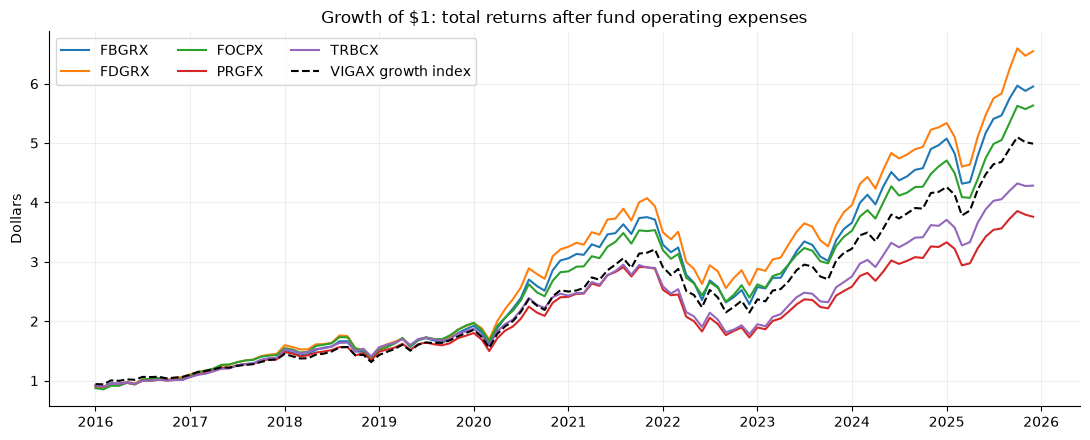

In [5]:
validation_rows = []
for row in highlights.itertuples():
    if row.fiscal_end > pd.Timestamp('2025-12-31') or row.fiscal_year < 2016: continue
    d = daily.loc[daily.ticker.eq(row.ticker)].set_index('date')
    previous_end = row.fiscal_end - pd.DateOffset(years=1)
    if d.index.min() > previous_end: continue
    use = d.loc[(d.index > previous_end) & (d.index <= row.fiscal_end)]
    observed = np.prod(1+use.net_return)-1
    adjusted = np.prod(1+use.adjusted_return)-1
    validation_rows.append(dict(ticker=row.ticker, fiscal_end=row.fiscal_end,
        published_pct=100*row.reported_return, reconstructed_pct=100*observed,
        adjusted_close_pct=100*adjusted,
        reconstructed_error_bp=10000*(observed-row.reported_return),
        adjusted_close_error_bp=10000*(adjusted-row.reported_return)))
validation = pd.DataFrame(validation_rows)
validation_summary = validation.groupby('ticker').agg(
    years=('fiscal_end','size'),
    max_reconstructed_error_bp=('reconstructed_error_bp', lambda s: s.abs().max()),
    max_adjusted_close_error_bp=('adjusted_close_error_bp', lambda s: s.abs().max()))
save_table(validation_summary.loc[ALL], 'table_return_validation_summary')
save_table(validation.set_index(['ticker','fiscal_end']), 'table_return_validation', show=False)
validation_exceptions = validation.loc[validation.reconstructed_error_bp.abs().gt(10)]
save_table(validation_exceptions.set_index(['ticker','fiscal_end']), 'table_fiscal_return_validation_exceptions')
print(f'Largest fiscal-year source difference: {validation.reconstructed_error_bp.abs().max():.2f} bp; '
      f'{len(validation_exceptions)} fund-years exceed 10 bp. Retained and disclosed; see adjusted-close sensitivity.')

sec_class = pd.read_csv(DATA/'sec_monthly_class_returns.csv')
sec_class['month'] = pd.PeriodIndex(sec_class.month, freq='M')
class_map = funds.class_id.to_dict()
sec_class = sec_class.loc[sec_class.apply(lambda r: r.class_id == class_map.get(r.ticker), axis=1)].copy()
assert not sec_class.duplicated(['ticker','month']).any()
sec_validation = sec_class.merge(net_full[ACTIVE].stack().rename('reconstructed').rename_axis(['month','ticker']).reset_index(),
                                 on=['month','ticker'], validate='one_to_one')
sec_validation['error_bp'] = (sec_validation.reconstructed-sec_validation.reported_return_pct/100)*10000
save_table(sec_validation.groupby('ticker').agg(months=('month','size'),
    max_error_bp=('error_bp', lambda s: s.abs().max())), 'table_SEC_return_validation')
assert sec_validation.error_bp.abs().max() < 10
descriptive = pd.DataFrame({'months': net.count(), 'mean_return_ann_pct': 1200*net.mean(),
    'compound_growth_ann_pct': 100*((1+net).prod()**(12/len(net))-1),
    'volatility_ann_pct': 100*np.sqrt(12)*net.std(ddof=1),
    'mean_expense_ann_pct': 100*fees.mean(),
    'Sharpe_ann': np.sqrt(12)*excess.mean()/net.std(ddof=1)})
save_table(descriptive, 'table_descriptive')
fig, ax = plt.subplots()
wealth = (1+net).cumprod()
for ticker in ACTIVE: ax.plot(wealth.index.to_timestamp(), wealth[ticker], label=ticker)
ax.plot(index_returns.index.to_timestamp(), (1+index_returns.VIGAX).cumprod(), color='black', ls='--', label='VIGAX growth index')
ax.set(title='Growth of $1: total returns after fund operating expenses', ylabel='Dollars', xlabel='')
ax.legend(ncol=3)
save_figure(fig, 'fig_net_wealth')

**What this does:** validates fiscal-year and monthly reconstructed total returns against independent disclosures, reports risk and fees, and plots net wealth with a growth-index reference.

## 5. CAPM, Fama–French and Carhart alphas

For the Carhart model (and the corresponding subsets for CAPM and FF3),
\[
r^{net}_{i,t}-r_{f,t}=\alpha_i+\beta_i(MKT-RF)_t+s_iSMB_t+h_iHML_t+m_iMOM_t+\epsilon_{i,t}.
\]
OLS estimates the coefficients. HAC standard errors allow serial correlation/heteroskedasticity with six monthly lags. Annual alpha is $12\hat\alpha$, regression tracking error is $\sqrt{12}\,SD(\hat\epsilon)$ with sample `ddof=1`, and the annual information/appraisal ratio is $\sqrt{12}\hat\alpha/SD(\hat\epsilon)$. The t-statistic is unchanged by annualization. This is residual TE, not the standard deviation of fund-minus-market returns, and the appraisal ratio is not the Sharpe ratio.

In [6]:
def fit_factor(y, columns, lags=HAC_LAGS):
    x = sm.add_constant(factors.loc[y.index, columns], has_constant='add')
    return sm.OLS(y.astype(float), x.astype(float)).fit(
        cov_type='HAC', cov_kwds={'maxlags':lags, 'use_correction':True}, use_t=True)

def summarize_fit(fit):
    alpha = float(fit.params['const']); se = float(fit.bse['const'])
    crit = stats.t.ppf(.975, fit.df_resid)
    te = float(np.std(fit.resid, ddof=1))
    return dict(alpha_ann_pct=1200*alpha, t_alpha=float(fit.tvalues['const']),
        p_alpha=float(fit.pvalues['const']), CI_low_ann_pct=1200*(alpha-crit*se),
        CI_high_ann_pct=1200*(alpha+crit*se),
        TE_ann_pct=100*np.sqrt(12)*te, IR_ann=np.sqrt(12)*alpha/te,
        R2=float(fit.rsquared), months=int(fit.nobs))

models = {}; result_rows = []
for ticker in ACTIVE:
    for model, cols in MODELS.items():
        fit = fit_factor(excess[ticker], cols)
        models[ticker,model] = fit
        result_rows.append(dict(ticker=ticker, model=model, **summarize_fit(fit)))
factor_results = pd.DataFrame(result_rows).set_index(['ticker','model'])
save_table(factor_results[['alpha_ann_pct','t_alpha','TE_ann_pct','IR_ann','R2','months']],
           'table_factor_regressions')
save_table(factor_results, 'table_factor_inference', show=False)
carhart = factor_results.xs('Carhart', level='model').copy()
carhart['BH_q_value'] = multipletests(carhart.p_alpha, alpha=.05, method='fdr_bh')[1]
save_table(carhart[['alpha_ann_pct','CI_low_ann_pct','CI_high_ann_pct','p_alpha','BH_q_value']],
           'table_carhart_uncertainty')

alpha_ann_pct  t_alpha  TE_ann_pct  IR_ann     R2  months
ticker model                                                             
FBGRX  CAPM            2.7093   0.8077      8.0646  0.3360 0.8396     120
       FF3             2.7453   1.4861      5.4039  0.5080 0.9280     120
       Carhart         2.8414   1.5581      5.3884  0.5273 0.9284     120
FDGRX  CAPM            3.5679   1.0337      7.9726  0.4475 0.8449     120
       FF3             3.7701   2.0947      5.2583  0.7170 0.9325     120
       Carhart         3.6032   1.9713      5.2101  0.6916 0.9338     120
FOCPX  CAPM            3.0300   1.0522      7.7507  0.3909 0.8291     120
       FF3             2.5649   1.4378      5.6609  0.4531 0.9088     120
       Carhart         2.6066   1.4330      5.6581  0.4607 0.9089     120
PRGFX  CAPM           -0.8932  -0.2882      6.9279 -0.1289 0.8535     120
       FF3            -1.3817  -0.7730      4.4671 -0.3093 0.9391     120
       Carhart        -1.2815  -0.7319      4.4467 -0.2882 0.9396     120
TRBCX  CAPM            0.5664   0.1718      7.3734  0.0768 0.8344     120
       FF3            -0.3456  -0.1921      4.6420 -0.0744 0.9344     120
       Carhart        -0.2875  -0.1629      4.6354 -0.0620 0.9346     120

,alpha_ann_pct,CI_low_ann_pct,CI_high_ann_pct,p_alpha,BH_q_value
ticker,,,,,
FBGRX,2.8414,-0.7709,6.4538,0.1220,0.2576
FDGRX,3.6032,-0.0174,7.2238,0.0511,0.2555
FOCPX,2.6066,-0.9965,6.2097,0.1546,0.2576
PRGFX,-1.2815,-4.7495,2.1865,0.4657,0.5821
TRBCX,-0.2875,-3.7838,3.2087,0.8709,0.8709


**What this does:** estimates all 15 regressions on the same 120 months, reports every required metric with the correct annualization, and separates five-fund multiple-testing evidence from point estimates.

### 5.1 What changes when factors are added?

Read the factor loadings alongside the intercept. A negative HML loading identifies a growth tilt, a negative SMB loading a large-company tilt, and MOM exposure can explain part of apparent winner performance. Their contribution also depends on the factors' realized average returns. Alpha can rise when an added exposure had an unfavorable premium. The following decomposition satisfies the OLS mean-return identity; it is an accounting explanation within the fitted model, not a causal identification of skill.

In [7]:
loadings = pd.DataFrame({t: models[t,'Carhart'].params for t in ACTIVE}).T
loadings = loadings.rename(columns={'const':'monthly_alpha'})
contributions = loadings[MODELS['Carhart']].mul(factors[MODELS['Carhart']].mean()*1200, axis=1)
contributions['alpha_ann_pct'] = carhart.alpha_ann_pct
contributions['sum_ann_pct'] = contributions.sum(axis=1)
contributions['mean_excess_ann_pct'] = excess.mean()*1200
save_table(loadings, 'table_factor_loadings')
save_table(contributions, 'table_return_decomposition')
alpha_by_model = factor_results.alpha_ann_pct.unstack('model').reindex(columns=MODELS)
for ticker in ACTIVE:
    a = alpha_by_model.loc[ticker]
    h = loadings.loc[ticker]
    display(Markdown(f'**{ticker}:** CAPM alpha {a.CAPM:.2f}% → FF3 {a.FF3:.2f}% → Carhart {a.Carhart:.2f}% per year. '
        f'Carhart loadings are market {h.Mkt_RF:.2f}, size {h.SMB:.2f}, value {h.HML:.2f}, momentum {h.Mom:.2f}. '
        f'The size/value/momentum contributions sum to {contributions.loc[ticker, ["SMB","HML","Mom"]].sum():.2f} percentage points per year; '
        'the market loading is re-estimated when the benchmark changes.'))

,monthly_alpha,Mkt_RF,SMB,HML,Mom
ticker,,,,,
FBGRX,0.0024,1.1539,0.0509,-0.4607,-0.0366
FDGRX,0.0030,1.1812,0.1231,-0.4327,0.0636
FOCPX,0.0022,1.0939,-0.0549,-0.3970,-0.0159
PRGFX,-0.0011,1.0673,-0.0681,-0.4027,-0.0382
TRBCX,-0.0002,1.0786,-0.1496,-0.4164,-0.0221


,Mkt_RF,SMB,HML,Mom,alpha_ann_pct,sum_ann_pct,mean_excess_ann_pct
ticker,,,,,,,
FBGRX,14.9442,-0.1054,0.2267,-0.0126,2.8414,17.8942,17.8942
FDGRX,15.2974,-0.2550,0.2129,0.0219,3.6032,18.8804,18.8804
FOCPX,14.1668,0.1137,0.1953,-0.0055,2.6066,17.0770,17.0770
PRGFX,13.8228,0.1412,0.1981,-0.0132,-1.2815,12.8674,12.8674
TRBCX,13.9692,0.3099,0.2049,-0.0076,-0.2875,14.1888,14.1888


**FBGRX:** CAPM alpha 2.71% → FF3 2.75% → Carhart 2.84% per year. Carhart loadings are market 1.15, size 0.05, value -0.46, momentum -0.04. The size/value/momentum contributions sum to 0.11 percentage points per year; the market loading is re-estimated when the benchmark changes.

**FDGRX:** CAPM alpha 3.57% → FF3 3.77% → Carhart 3.60% per year. Carhart loadings are market 1.18, size 0.12, value -0.43, momentum 0.06. The size/value/momentum contributions sum to -0.02 percentage points per year; the market loading is re-estimated when the benchmark changes.

**FOCPX:** CAPM alpha 3.03% → FF3 2.56% → Carhart 2.61% per year. Carhart loadings are market 1.09, size -0.05, value -0.40, momentum -0.02. The size/value/momentum contributions sum to 0.30 percentage points per year; the market loading is re-estimated when the benchmark changes.

**PRGFX:** CAPM alpha -0.89% → FF3 -1.38% → Carhart -1.28% per year. Carhart loadings are market 1.07, size -0.07, value -0.40, momentum -0.04. The size/value/momentum contributions sum to 0.33 percentage points per year; the market loading is re-estimated when the benchmark changes.

**TRBCX:** CAPM alpha 0.57% → FF3 -0.35% → Carhart -0.29% per year. Carhart loadings are market 1.08, size -0.15, value -0.42, momentum -0.02. The size/value/momentum contributions sum to 0.51 percentage points per year; the market loading is re-estimated when the benchmark changes.

**What this does:** shows fund-specific exposures and realized premium contributions, then explains the actual direction of each alpha change rather than assuming every added factor lowers alpha.

## 6. Gross alpha, net alpha and whether the expense is covered

Re-estimate all three models using `net return + annual expense / 12`. This reconstructs returns before the reported operating expenses, while trading costs remain in the return. With time-varying expenses, gross alpha minus net alpha need not equal the simple average expense exactly, because expenses can covary with factors. The add-back is mechanical evidence about cost incidence; a positive gross intercept is not by itself proof of manager skill.

,mean_fee_ann_pct,Carhart_gross_alpha_ann_pct,Carhart_net_alpha_ann_pct,net_CI_low_pct,net_CI_high_pct,point_fee_verdict,statistical_evidence
ticker,,,,,,,
FBGRX,0.7088,3.5526,2.8414,-0.7709,6.4538,Appears justified,Inconclusive at 95%
FDGRX,0.7693,4.3751,3.6032,-0.0174,7.2238,Appears justified,Inconclusive at 95%
FOCPX,0.8160,3.4235,2.6066,-0.9965,6.2097,Appears justified,Inconclusive at 95%
PRGFX,0.6560,-0.6250,-1.2815,-4.7495,2.1865,Not covered by estimated alpha,Inconclusive at 95%
TRBCX,0.6980,0.4109,-0.2875,-3.7838,3.2087,Not covered by estimated alpha,Inconclusive at 95%


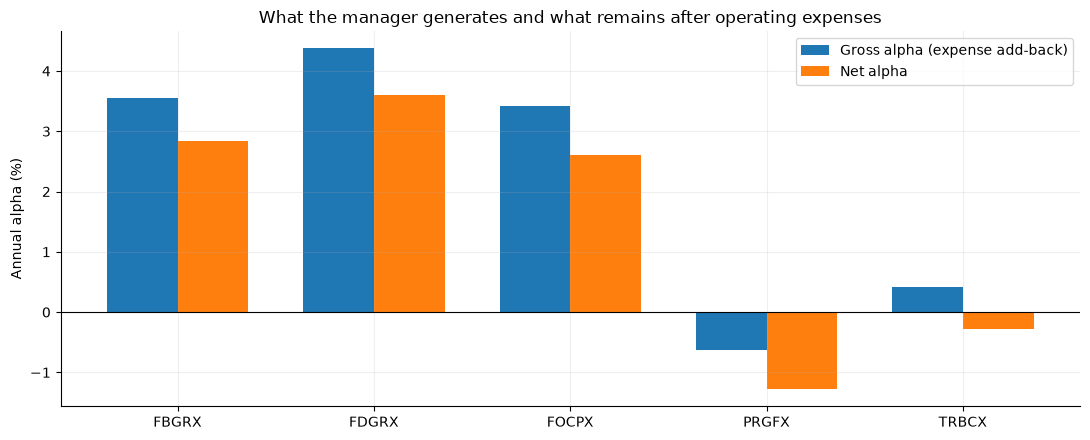

In [8]:
gross_models = {}; gross_rows = []
for ticker in ACTIVE:
    for model, cols in MODELS.items():
        fit = fit_factor(gross_excess[ticker], cols)
        gross_models[ticker,model] = fit
        gross_rows.append(dict(ticker=ticker, model=model, **summarize_fit(fit)))
gross_results = pd.DataFrame(gross_rows).set_index(['ticker','model'])
fee_alpha = pd.DataFrame({'mean_fee_ann_pct': fees.mean()*100,
    'Carhart_gross_alpha_ann_pct': gross_results.xs('Carhart',level='model').alpha_ann_pct,
    'Carhart_net_alpha_ann_pct': carhart.alpha_ann_pct,
    'net_CI_low_pct': carhart.CI_low_ann_pct, 'net_CI_high_pct': carhart.CI_high_ann_pct})
fee_alpha['point_fee_verdict'] = np.where(fee_alpha.Carhart_net_alpha_ann_pct>=0,
                                        'Appears justified', 'Not covered by estimated alpha')
fee_alpha['statistical_evidence'] = np.select(
    [fee_alpha.net_CI_low_pct>0, fee_alpha.net_CI_high_pct<0],
    ['Positive net alpha supported', 'Negative net alpha supported'], default='Inconclusive at 95%')
save_table(gross_results, 'table_gross_factor_results', show=False)
save_table(fee_alpha, 'table_gross_net_fees')
fig, ax = plt.subplots()
xx = np.arange(len(ACTIVE)); width=.36
ax.bar(xx-width/2, fee_alpha.Carhart_gross_alpha_ann_pct, width, label='Gross alpha (expense add-back)')
ax.bar(xx+width/2, fee_alpha.Carhart_net_alpha_ann_pct, width, label='Net alpha')
ax.axhline(0,color='black',lw=.8)
ax.set(xticks=xx, xticklabels=ACTIVE, ylabel='Annual alpha (%)', title='What the manager generates and what remains after operating expenses')
ax.legend()
save_figure(fig, 'fig_gross_net_alpha')

**What this does:** re-estimates gross alphas, presents the fee-coverage verdict beside its uncertainty for every fund, and compares before/after-expense performance graphically.

## 7. An implementable index-fund benchmark

Fit total net fund returns to total net returns of VFIAX, VIGAX, VVIAX and VSMAX:
\[
r_{i,t}=a_i+\sum_jw_{ij}r_{j,t}^{index}+e_{i,t},\quad w_{ij}\ge0,\quad\sum_jw_{ij}=1.
\]
The intercept is fitted jointly: minimize squared **demeaned** errors to find weights, then recover the mean return difference. Omitting the intercept when fitting weights would confound risk fit and mean performance. These are monthly constant-weight portfolios, rebalanced monthly before taxes and external trading frictions. Unlike long–short factors, the index funds are buyable exposures, though fund minimums and access still matter.

Index returns already reflect their own expenses. The weighted expense is reported as a cost comparison and is **not** subtracted again from index returns. The benchmark alpha is a total-return mean difference against the fitted style portfolio, not another CAPM intercept. Fit and residual tracking error determine how credible “similar exposure” is; low cost alone does not imply exact replication.

ticker,VFIAX,VIGAX,VVIAX,VSMAX
ticker,,,,
FBGRX,0.0000,1.0000,0.0000,0.0000
FDGRX,0.0000,0.9680,0.0000,0.0320
FOCPX,0.0000,1.0000,0.0000,0.0000
PRGFX,0.0000,0.9899,0.0000,0.0101
TRBCX,0.0000,1.0000,0.0000,0.0000


,index_alpha_ann_pct,R2,residual_TE_ann_pct,fund_fee_ann_pct,benchmark_fee_ann_pct,fee_saving_pp
ticker,,,,,,
FBGRX,2.2146,0.9460,4.6869,0.7088,0.0510,0.6578
FDGRX,3.3901,0.9328,5.2511,0.7693,0.0510,0.7183
FOCPX,1.3973,0.9313,4.9192,0.8160,0.0510,0.7650
PRGFX,-2.7527,0.9603,3.6120,0.6560,0.0510,0.6050
TRBCX,-1.4909,0.9576,3.7417,0.6980,0.0510,0.6470


**Investable comparison:** growth-index weights range from 96.8% to 100.0%, and fitted R² ranges from 0.931 to 0.960. The cheap growth exposure captures much of the co-movement, but residual tracking error remains. A manager should be assessed against that remaining difference, not credited for the entire growth-stock return.

,mean_fee_ann_pct
ticker,
VFIAX,0.0400
VIGAX,0.0510
VVIAX,0.0510
VSMAX,0.0510


,CAPM,FF3,Carhart,Index funds
ticker,,,,
FBGRX,2.7093,2.7453,2.8414,2.2146
FDGRX,3.5679,3.7701,3.6032,3.3901
FOCPX,3.0300,2.5649,2.6066,1.3973
PRGFX,-0.8932,-1.3817,-1.2815,-2.7527
TRBCX,0.5664,-0.3456,-0.2875,-1.4909


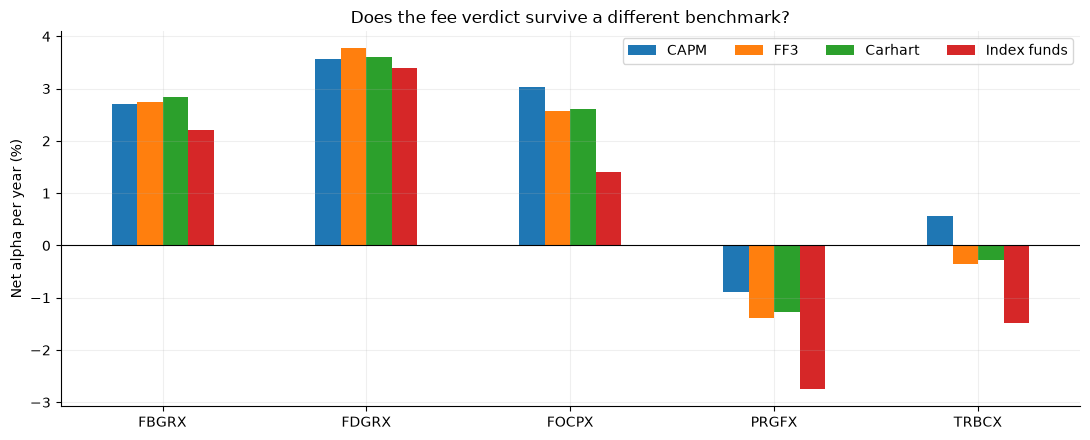

In [9]:
def fit_index(y, x):
    # Percentage scaling improves optimizer precision without changing the solution.
    yc = (y-y.mean()).to_numpy()*100
    xc = (x-x.mean()).to_numpy()*100
    def objective(w): return np.mean((yc-xc@w)**2)
    def jac(w): return 2*xc.T@(xc@w-yc)/len(yc)
    fit = minimize(objective, np.repeat(1/x.shape[1],x.shape[1]), jac=jac,
        method='SLSQP', bounds=[(0,1)]*x.shape[1],
        constraints={'type':'eq', 'fun':lambda w:w.sum()-1, 'jac':lambda w:np.ones_like(w)},
        options={'ftol':1e-12, 'maxiter':2000})
    assert fit.success, fit.message
    w = pd.Series(fit.x,index=x.columns)
    diff = y-x@w; alpha = diff.mean(); residual = diff-alpha
    return dict(weights=w, alpha=alpha, residual=residual,
                R2=1-np.sum(residual**2)/np.sum((y-y.mean())**2), objective=fit.fun)

index_fits = {}; index_rows=[]; weight_rows=[]
for ticker in ACTIVE:
    fit=fit_index(net[ticker],index_returns); index_fits[ticker]=fit
    w=fit['weights']; weight_rows.append(w.rename(ticker))
    benchmark_fee = expense_full.loc[MONTHS,INDEX].mul(w,axis=1).sum(axis=1).mean()*100
    index_rows.append(dict(ticker=ticker, index_alpha_ann_pct=1200*fit['alpha'],
        R2=fit['R2'], residual_TE_ann_pct=100*np.sqrt(12)*fit['residual'].std(ddof=1),
        fund_fee_ann_pct=100*fees[ticker].mean(), benchmark_fee_ann_pct=benchmark_fee,
        fee_saving_pp=100*fees[ticker].mean()-benchmark_fee))
weights=pd.DataFrame(weight_rows).loc[ACTIVE,INDEX]
index_results=pd.DataFrame(index_rows).set_index('ticker')
save_table(weights,'table_index_weights')
save_table(index_results,'table_index_benchmark')
display(Markdown(f'**Investable comparison:** growth-index weights range from {weights.VIGAX.min():.1%} to {weights.VIGAX.max():.1%}, '
    f'and fitted R² ranges from {index_results.R2.min():.3f} to {index_results.R2.max():.3f}. '
    'The cheap growth exposure captures much of the co-movement, but residual tracking error remains. '
    'A manager should be assessed against that remaining difference, not credited for the entire growth-stock return.'))
save_table(pd.DataFrame({'mean_fee_ann_pct':expense_full.loc[MONTHS,INDEX].mean()*100}), 'table_index_fees')
combined_alpha = alpha_by_model.join(index_results.index_alpha_ann_pct.rename('Index funds'))
save_table(combined_alpha,'table_benchmark_comparison')
fig, ax=plt.subplots()
combined_alpha.plot.bar(ax=ax,rot=0)
ax.axhline(0,color='black',lw=.8)
ax.set(ylabel='Net alpha per year (%)',title='Does the fee verdict survive a different benchmark?',xlabel='')
ax.legend(ncol=4)
save_figure(fig,'fig_alpha_by_benchmark')

**What this does:** fits the non-negative fully invested benchmark with a free intercept, checks exposures and costs, and compares net alpha across all four benchmark definitions.

### 7.1 A benchmark fitted before the evaluation period

The full-sample weights describe exposures in hindsight. As a stricter check, fit them using 2016–2020 only, freeze them, and evaluate the mean fund-minus-benchmark return in 2021–2025. This is a historical holdout, not a fully tradable fund-selection strategy: the five case studies were chosen using present-day data availability. A fixed style portfolio can also become stale if the active manager changes style.

In [10]:
oos_rows=[]
for ticker in ACTIVE:
    train = net.loc['2016-01':'2020-12',ticker]
    w=fit_index(train,index_returns.loc[train.index])['weights']
    test=net.loc['2021-01':'2025-12',ticker]
    active_diff=test-index_returns.loc[test.index]@w
    fit=sm.OLS(active_diff, pd.DataFrame({'const':1.},index=test.index)).fit(
        cov_type='HAC',cov_kwds={'maxlags':HAC_LAGS,'use_correction':True},use_t=True)
    s=summarize_fit(fit)
    oos_rows.append(dict(ticker=ticker, holdout_alpha_ann_pct=s['alpha_ann_pct'],
        t_alpha=s['t_alpha'], CI_low_ann_pct=s['CI_low_ann_pct'], CI_high_ann_pct=s['CI_high_ann_pct'],
        months=s['months']))
oos_index=pd.DataFrame(oos_rows).set_index('ticker')
save_table(oos_index,'table_index_holdout')
display(Markdown('**Holdout interpretation:** the frozen benchmark comparison is evaluated only on 2021–2025. '
    'Compare its mean differences and intervals with the second-half Carhart table in Section 9: a fund may have positive factor alpha '
    'while scarcely beating, or trailing, a growth index. That is evidence that the benchmark definition matters, rather than a contradiction in return arithmetic.'))

,holdout_alpha_ann_pct,t_alpha,CI_low_ann_pct,CI_high_ann_pct,months
ticker,,,,,
FBGRX,0.3280,0.1352,-4.5257,5.1816,60
FDGRX,1.2433,0.5276,-3.4722,5.9588,60
FOCPX,-0.0010,-0.0006,-3.5559,3.5538,60
PRGFX,-4.6651,-2.2669,-8.7829,-0.5473,60
TRBCX,-2.5420,-1.2300,-6.6774,1.5935,60


**Holdout interpretation:** the frozen benchmark comparison is evaluated only on 2021–2025. Compare its mean differences and intervals with the second-half Carhart table in Section 9: a fund may have positive factor alpha while scarcely beating, or trailing, a growth index. That is evidence that the benchmark definition matters, rather than a contradiction in return arithmetic.

**What this does:** prevents benchmark weights from using the evaluation returns and reports uncertainty for the subsequent mean active return conditional on the frozen portfolio.

## 8. Fees, turnover and the US fund fee distribution

With five funds from two families, a cross-sectional fee regression has almost no power and substantial confounding. We therefore show the five observations, descriptive correlations, and whether each fund's gross alpha leaves enough net alpha. We do not interpret a fee slope as causal or as a replication of Carhart's large-universe result.

ICI Figure 2 supplies the 10th percentile, median and 90th percentile across equity fund **share classes**, plus the corresponding growth distribution. Its equity group includes US-registered world/sector funds; it is not a pure domestic-large-growth universe. Compare both groups, label the universe and weighting, and report bands rather than invent exact percentiles between published quantiles. Use each fund's fiscal expense for the latest fiscal year ending in 2025 for this cross-sectional snapshot, not its 10-year average. Fund families' fiscal year-ends differ. The 2025 industry distribution is descriptive context, not information used to select funds in 2016.

,year,p10_pct,median_pct,p90_pct,asset_weighted_mean_pct,simple_mean_pct,source_url
category,,,,,,,
Equity mutual funds,2025,0.5100,0.9900,1.8400,0.4000,1.0800,https://www.ici.org/system/files/2026-03/per32-01.pdf
Growth,2025,0.6000,0.9800,1.7500,0.5700,1.0600,https://www.ici.org/system/files/2026-03/per32-01.pdf


,FY_2025_end,FY_2025_fee_pct,FY_2025_turnover_pct,equity_fee_band,growth_fee_band
ticker,,,,,
FBGRX,2025-07-31,0.6100,34.0000,10th to 50th percentile,10th to 50th percentile
FDGRX,2025-11-30,0.6900,16.0000,10th to 50th percentile,10th to 50th percentile
FOCPX,2025-07-31,0.7300,53.0000,10th to 50th percentile,10th to 50th percentile
PRGFX,2025-12-31,0.6600,35.2000,10th to 50th percentile,10th to 50th percentile
TRBCX,2025-12-31,0.7000,18.3000,10th to 50th percentile,10th to 50th percentile


,mean_fee_ann_pct,Carhart_gross_alpha_ann_pct,Carhart_net_alpha_ann_pct,mean_turnover_pct
ticker,,,,
FBGRX,0.7088,3.5526,2.8414,37.8000
FDGRX,0.7693,4.3751,3.6032,16.2000
FOCPX,0.8160,3.4235,2.6066,41.2000
PRGFX,0.6560,-0.6250,-1.2815,34.7700
TRBCX,0.6980,0.4109,-0.2875,24.7500


,Carhart_gross_alpha_ann_pct,Carhart_net_alpha_ann_pct
row,,
mean_fee_ann_pct,0.7751,0.7633
mean_turnover_pct,-0.1106,-0.1138


**Fee interpretation:** the five-fund correlation between mean expense and gross Carhart alpha is 0.78. This is a convenience-sample association, and it need not reproduce the lecture’s negative large-universe fee slope. Judge the individual fee against the net-alpha table; neither a high nor a low fee establishes value by itself.

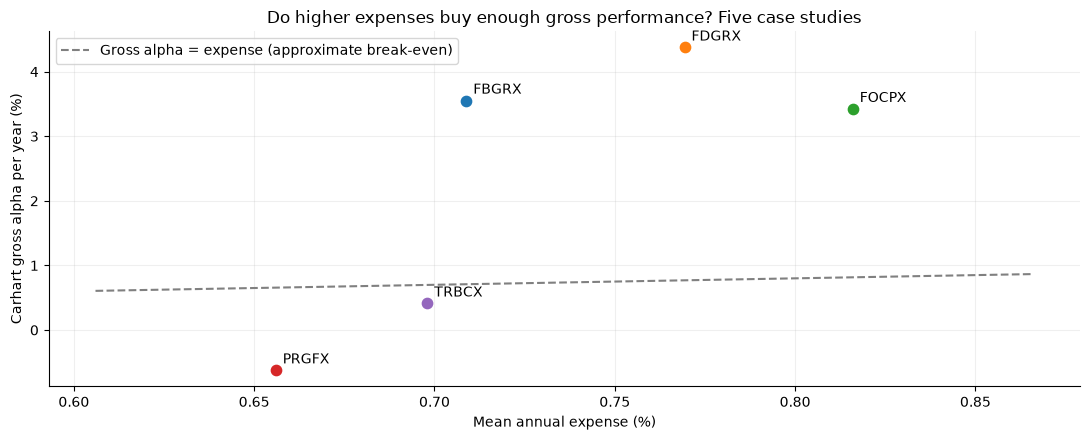

In [11]:
ici=pd.read_csv(DATA/'ici_fee_distribution.csv').set_index('category')
snapshot=(highlights.loc[highlights.ticker.isin(ACTIVE) & highlights.fiscal_year.eq(2025)]
          .set_index('ticker').loc[ACTIVE])
fee_context=pd.DataFrame({'FY_2025_end':snapshot.fiscal_end,
    'FY_2025_fee_pct':snapshot.expense*100, 'FY_2025_turnover_pct':snapshot.turnover*100})
def fee_band(value,row):
    if value<row.p10_pct:return 'Below 10th percentile'
    if value<row.median_pct:return '10th to 50th percentile'
    if value<row.p90_pct:return '50th to 90th percentile'
    return 'At/above 90th percentile'
for category,label in [('Equity mutual funds','equity_fee_band'),('Growth','growth_fee_band')]:
    fee_context[label]=fee_context.FY_2025_fee_pct.map(lambda v:fee_band(v,ici.loc[category]))
save_table(ici,'table_industry_fee_distribution')
save_table(fee_context,'table_fund_fee_context')
fee_performance=fee_alpha[['mean_fee_ann_pct','Carhart_gross_alpha_ann_pct','Carhart_net_alpha_ann_pct']].copy()
fee_performance['mean_turnover_pct']=highlights.loc[highlights.ticker.isin(ACTIVE) &
    highlights.fiscal_year.between(2016,2025)].groupby('ticker').turnover.mean()*100
save_table(fee_performance,'table_fee_performance')
fee_correlations=fee_performance.corr().loc[['mean_fee_ann_pct','mean_turnover_pct'],
    ['Carhart_gross_alpha_ann_pct','Carhart_net_alpha_ann_pct']]
save_table(fee_correlations,'table_fee_correlations_descriptive')
display(Markdown(f'**Fee interpretation:** the five-fund correlation between mean expense and gross Carhart alpha is '
    f'{fee_correlations.loc["mean_fee_ann_pct","Carhart_gross_alpha_ann_pct"]:.2f}. '
    'This is a convenience-sample association, and it need not reproduce the lecture’s negative large-universe fee slope. '
    'Judge the individual fee against the net-alpha table; neither a high nor a low fee establishes value by itself.'))
fig, ax=plt.subplots()
for ticker,row in fee_performance.iterrows():
    ax.scatter(row.mean_fee_ann_pct,row.Carhart_gross_alpha_ann_pct,s=55)
    ax.annotate(ticker,(row.mean_fee_ann_pct,row.Carhart_gross_alpha_ann_pct),xytext=(5,5),textcoords='offset points')
lo,hi=fee_performance.mean_fee_ann_pct.min()-.05,fee_performance.mean_fee_ann_pct.max()+.05
ax.plot([lo,hi],[lo,hi],color='grey',ls='--',label='Gross alpha = expense (approximate break-even)')
ax.set(xlabel='Mean annual expense (%)',ylabel='Carhart gross alpha per year (%)',
       title='Do higher expenses buy enough gross performance? Five case studies')
ax.legend(loc='best')
save_figure(fig,'fig_fee_gross_alpha')

**What this does:** places every fee in published equity and growth distribution bands, examines available turnover, and keeps the five-fund fee/performance relationship explicitly descriptive.

## 9. Persistence, fund flows and Berk and Green
### 9.1 Do first-half winners keep their alpha?

Estimate net Carhart alpha independently in each 60-month half. Compare ranks using Spearman correlation, retaining individual standard errors. There are only five rankings and the funds share exposures and families, so the rank statistic is descriptive rather than decisive evidence of predictability. A paired sign/rank change can reflect sampling noise or style changes. Selection on today's surviving funds remains even though second-half returns are not used in first-half estimation.

,2016–2020 alpha_pct,2016–2020 t,2021–2025 alpha_pct,2021–2025 t,first_rank,second_rank
ticker,,,,,,
FBGRX,0.9486,0.4630,5.0270,1.5820,2.0000,2.0000
FDGRX,1.2402,0.4448,5.5023,2.0121,1.0000,1.0000
FOCPX,-0.2032,-0.0683,4.5203,1.7337,3.0000,3.0000
PRGFX,-1.1052,-0.4977,0.2677,0.0911,5.0000,5.0000
TRBCX,-0.2778,-0.1146,1.8483,0.6932,4.0000,4.0000


Spearman rank correlation across five funds: 1.000 (descriptive; N=5)


**Persistence interpretation:** rank correlation is 1.00. The table identifies whether the same case-study funds remain ahead; this does not mean the magnitude or sign of alpha is stable. The individual t-statistics, only five correlated observations and selection on surviving public records limit what this says about choosing future winners.

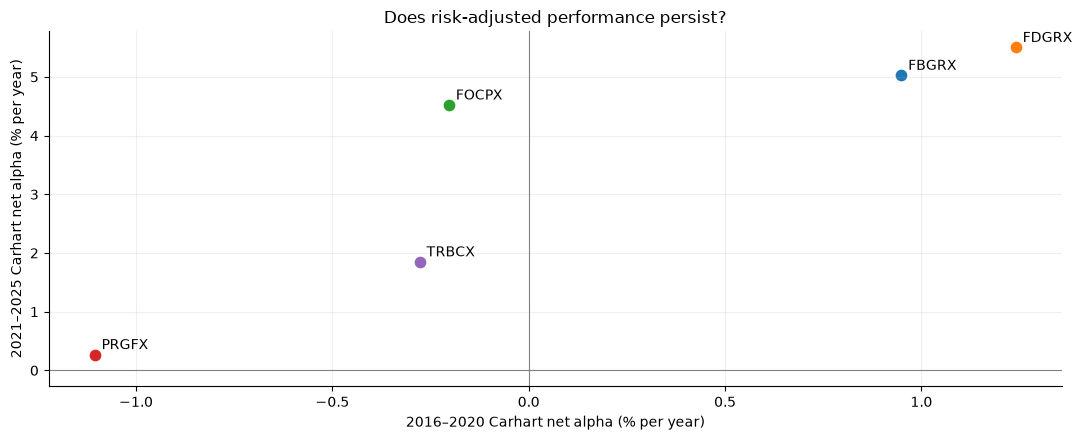

In [12]:
persistence=pd.DataFrame(index=ACTIVE)
for label,(start,end) in HALVES.items():
    for ticker in ACTIVE:
        y=excess.loc[start:end,ticker];s=summarize_fit(fit_factor(y,MODELS['Carhart']))
        persistence.loc[ticker,label+' alpha_pct']=s['alpha_ann_pct']
        persistence.loc[ticker,label+' t']=s['t_alpha']
first_col,second_col='2016–2020 alpha_pct','2021–2025 alpha_pct'
persistence['first_rank']=persistence[first_col].rank(ascending=False)
persistence['second_rank']=persistence[second_col].rank(ascending=False)
rank_rho=float(stats.spearmanr(persistence[first_col],persistence[second_col]).statistic)
save_table(persistence,'table_persistence')
print(f'Spearman rank correlation across five funds: {rank_rho:.3f} (descriptive; N=5)')
display(Markdown(f'**Persistence interpretation:** rank correlation is {rank_rho:.2f}. '
    'The table identifies whether the same case-study funds remain ahead; this does not mean the magnitude or sign of alpha is stable. '
    'The individual t-statistics, only five correlated observations and selection on surviving public records limit what this says about choosing future winners.'))
fig, ax=plt.subplots()
for ticker,row in persistence.iterrows():
    ax.scatter(row[first_col],row[second_col],s=55)
    ax.annotate(ticker,(row[first_col],row[second_col]),xytext=(5,4),textcoords='offset points')
ax.axhline(0,color='grey',lw=.8);ax.axvline(0,color='grey',lw=.8)
ax.set(xlabel='2016–2020 Carhart net alpha (% per year)',ylabel='2021–2025 Carhart net alpha (% per year)',
       title='Does risk-adjusted performance persist?')
save_figure(fig,'fig_persistence')

**What this does:** re-estimates both halves separately, compares fund rankings, and shows whether the same funds retain positive estimated alpha.

### 9.2 Asset-based flow calculation at the frequency actually observed

The requested monthly formula is
\[
Flow_{i,t}=TNA_{i,t}-TNA_{i,t-1}(1+r^{net}_{i,t}).
\]
It requires assets and returns for the **same share class and consecutive months**. The local data contain annual class TNA for all five funds and quarterly aggregate TNA for two fund series. Consequently no observed pair supports the exact monthly class calculation. The code audits this explicitly instead of silently treating a year-to-year change as one month or interpolating assets.

For consecutive fiscal years, apply the identical formula with the compounded return over that fiscal year. This is an **annual residual-flow estimate**, not monthly flows or exact net subscriptions. It can include effects of flow timing, share-class exchanges, mergers and in-kind transfers. Relate it to the **previous** fiscal year's total return, not the same year's return used mechanically in its construction. Lagged assets scale the dollar estimate. Each fund needs complete return coverage at both horizons.

In [13]:
def inferred_flow(tna_end,tna_previous,period_return):
    return tna_end-tna_previous*(1+period_return)

annual_assets=highlights.loc[highlights.ticker.isin(ACTIVE) &
    highlights.fiscal_end.le(pd.Timestamp('2025-12-31'))].copy()
availability=[];annual_rows=[]
for ticker in ACTIVE:
    h=annual_assets.loc[annual_assets.ticker.eq(ticker)].sort_values('fiscal_end')
    month_ids=h.fiscal_end.dt.to_period('M').astype('int64')
    monthly_pairs=int(month_ids.diff().eq(1).sum())
    availability.append(dict(ticker=ticker, annual_TNA_observations=len(h),
        consecutive_monthly_class_TNA_pairs=monthly_pairs,
        exact_monthly_flow_status='Unavailable: no consecutive monthly class TNA'))
    d=daily.loc[daily.ticker.eq(ticker)].set_index('date').net_return
    for previous,current in zip(h.itertuples(),h.iloc[1:].itertuples()):
        if (current.fiscal_end.to_period('M')-previous.fiscal_end.to_period('M')).n != 12:continue
        period=d.loc[(d.index>previous.fiscal_end)&(d.index<=current.fiscal_end)]
        lag_start=previous.fiscal_end-pd.DateOffset(years=1)
        if d.index.min()>lag_start:continue
        lag_period=d.loc[(d.index>lag_start)&(d.index<=previous.fiscal_end)]
        r=np.prod(1+period)-1; lag_r=np.prod(1+lag_period)-1
        flow=inferred_flow(current.net_assets,previous.net_assets,r)
        annual_rows.append(dict(ticker=ticker,fiscal_end=current.fiscal_end,
            prior_TNA_usd=previous.net_assets,TNA_usd=current.net_assets,
            period_return=r,prior_year_return=lag_r,inferred_flow_usd=flow,
            inferred_flow_pct_prior_TNA=100*flow/previous.net_assets))
flow_availability=pd.DataFrame(availability).set_index('ticker')
annual_flow=pd.DataFrame(annual_rows).set_index(['ticker','fiscal_end']).sort_index()
save_table(flow_availability,'table_monthly_TNA_availability')
save_table(annual_flow,'table_annual_inferred_flows',show=False)
annual_flow_summary=annual_flow.groupby('ticker').agg(
    fiscal_years=('inferred_flow_usd','size'),
    mean_inferred_flow_pct=('inferred_flow_pct_prior_TNA','mean'))
annual_flow_summary['corr_with_prior_year_return']=[
    annual_flow.loc[t].inferred_flow_pct_prior_TNA.corr(annual_flow.loc[t].prior_year_return) for t in annual_flow_summary.index]
save_table(annual_flow_summary,'table_annual_flow_summary')

,annual_TNA_observations,consecutive_monthly_class_TNA_pairs,exact_monthly_flow_status
ticker,,,
FBGRX,10,0,Unavailable: no consecutive monthly class TNA
FDGRX,10,0,Unavailable: no consecutive monthly class TNA
FOCPX,10,0,Unavailable: no consecutive monthly class TNA
PRGFX,10,0,Unavailable: no consecutive monthly class TNA
TRBCX,10,0,Unavailable: no consecutive monthly class TNA


,fiscal_years,mean_inferred_flow_pct,corr_with_prior_year_return
ticker,,,
FBGRX,9,-1.4567,0.2608
FDGRX,9,-8.1216,0.0896
FOCPX,9,-8.8012,-0.2101
PRGFX,9,-27.5282,0.0885
TRBCX,9,-12.7625,0.3976


**What this does:** implements the required arithmetic, audits the missing monthly asset pairs, and calculates only supported annual class flows with properly lagged performance predictors.

### 9.3 Actual reported monthly flows for two fund series

N-PORT reports sales, redemptions and reinvestments for each of the preceding three months in a quarterly filing. Net **external** reported flow is sales minus the **withdrawal magnitude** of redemptions: exclude reinvestments, which recycle distributions rather than represent new investor cash. The source files use negative signed redemptions in 2019–2023 and positive withdrawal amounts in 2024–2025. Normalize redemptions to their absolute withdrawal magnitude, preserve the original field, and log the affected records. Sales are non-negative in this extract. Small signed reinvestment corrections are retained in the source but excluded from external flows. These flows aggregate all share classes in a portfolio series. Quarterly series assets are not combined with retail-class returns to pretend the monthly TNA formula is observed.

Scale each month's reported external flow by TNA at the **previous quarter-end**, an observed common denominator known before all three flow months. This is not the usual flow divided by last month's TNA. Regress that percentage on the retail class's lagged compounded 12-month return as a clearly labeled proxy for the portfolio's past performance. Use six-lag HAC inference within each fund, with no causal claim. Class expenses and within-series switches can differ. N-PORT availability limits this analysis to a later period, and only two of the five case studies.

,reported_months,available_prior_quarter_TNA
ticker,,
PRGFX,78,75
TRBCX,78,75


,first_month,last_month,months,slope_flow_pp_per_1pp_prior_return,t_slope,p_slope,R2,mean_reported_flow_pct
ticker,,,,,,,,
PRGFX,2019-10,2025-12,75,-0.0069,-1.1338,0.2606,0.0343,-1.2539
TRBCX,2019-10,2025-12,75,0.0209,2.3193,0.0232,0.2050,-1.1187


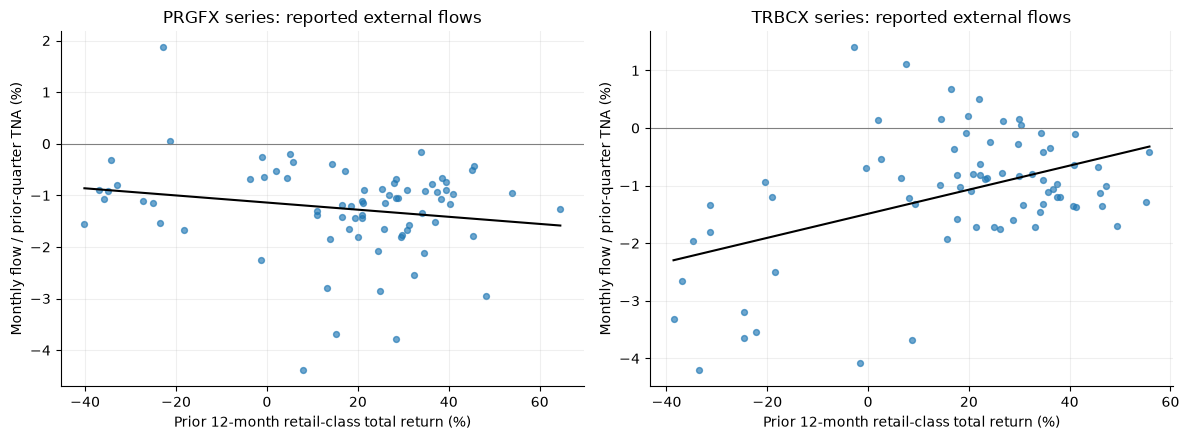

**PRGFX flow evidence:** the association with past returns is negative, slope -0.007 flow percentage points per 1 pp prior return (HAC t=-1.13, p=0.261). Mean monthly external flow is -1.25% of previous-quarter assets. This is a series-level association, not evidence that investor flows caused performance to change.

**TRBCX flow evidence:** the association with past returns is positive, slope 0.021 flow percentage points per 1 pp prior return (HAC t=2.32, p=0.023). Mean monthly external flow is -1.12% of previous-quarter assets. This is a series-level association, not evidence that investor flows caused performance to change.

In [14]:
reported_flow=pd.read_csv(DATA/'sec_reported_monthly_flows.csv')
series_assets=pd.read_csv(DATA/'sec_quarterly_series_assets.csv')
reported_flow['month']=pd.PeriodIndex(reported_flow.month,freq='M')
reported_flow['quarter_end']=pd.PeriodIndex(reported_flow.quarter_end,freq='M')
series_assets['asset_month']=pd.PeriodIndex(pd.to_datetime(series_assets.date),freq='M')
for c in ['sales_usd','redemptions_usd','reinvestment_usd']:
    reported_flow[c]=pd.to_numeric(reported_flow[c],errors='coerce')
assert reported_flow[['sales_usd','redemptions_usd','reinvestment_usd']].notna().all().all()
assert not reported_flow.duplicated(['ticker','month']).any()
assert not series_assets.duplicated(['ticker','asset_month']).any()
reported_flow['prior_quarter_end']=reported_flow.quarter_end-3
reported_flow=reported_flow.merge(series_assets[['ticker','asset_month','net_assets_usd']],
    left_on=['ticker','prior_quarter_end'],right_on=['ticker','asset_month'],how='left',validate='many_to_one')
assert (reported_flow.sales_usd>=0).all()
reported_flow['redemption_withdrawal_usd']=reported_flow.redemptions_usd.abs()
log('reported monthly flows', 'Normalize legacy signed redemptions to withdrawal magnitude',
    reported_flow.redemptions_usd.lt(0).sum(),len(reported_flow),
    '2019–2023 uses negative signs; 2024–2025 uses positive withdrawal amounts. Raw fields retained.')
reported_flow['net_external_flow_usd']=reported_flow.sales_usd-reported_flow.redemption_withdrawal_usd
reported_flow['flow_pct_prior_quarter_TNA']=100*reported_flow.net_external_flow_usd/reported_flow.net_assets_usd
lag_return=(1+net_full[ACTIVE]).rolling(12,min_periods=12).apply(np.prod,raw=True).shift(1)-1
reported_flow['prior_12m_return_pct']=[100*lag_return.loc[m,t] for m,t in zip(reported_flow.month,reported_flow.ticker)]
flow_counts=reported_flow.groupby('ticker').agg(
    reported_months=('month','size'),available_prior_quarter_TNA=('net_assets_usd','count'))
save_table(flow_counts,'table_reported_flow_coverage')
flow_panel=reported_flow.dropna(subset=['flow_pct_prior_quarter_TNA','prior_12m_return_pct']).sort_values(['ticker','month'])
flow_models={};flow_results=[]
for ticker,g in flow_panel.groupby('ticker'):
    x=sm.add_constant(g[['prior_12m_return_pct']],has_constant='add')
    fit=sm.OLS(g.flow_pct_prior_quarter_TNA,x).fit(cov_type='HAC',
        cov_kwds={'maxlags':HAC_LAGS,'use_correction':True},use_t=True)
    flow_models[ticker]=fit
    flow_results.append(dict(ticker=ticker,first_month=str(g.month.min()),last_month=str(g.month.max()),
        months=len(g),slope_flow_pp_per_1pp_prior_return=fit.params['prior_12m_return_pct'],
        t_slope=fit.tvalues['prior_12m_return_pct'],p_slope=fit.pvalues['prior_12m_return_pct'],R2=fit.rsquared,
        mean_reported_flow_pct=g.flow_pct_prior_quarter_TNA.mean()))
flow_regressions=pd.DataFrame(flow_results).set_index('ticker')
save_table(flow_regressions,'table_reported_flow_regressions')
save_table(reported_flow.set_index(['ticker','month']), 'table_reported_monthly_flows',show=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,(ticker,g) in zip(axes,flow_panel.groupby('ticker')):
    ax.scatter(g.prior_12m_return_pct,g.flow_pct_prior_quarter_TNA,s=18,alpha=.65)
    fit=flow_models[ticker];xx=np.linspace(g.prior_12m_return_pct.min(),g.prior_12m_return_pct.max(),100)
    ax.plot(xx,fit.params['const']+fit.params['prior_12m_return_pct']*xx,color='black')
    ax.axhline(0,color='grey',lw=.8)
    ax.set(title=ticker+' series: reported external flows',xlabel='Prior 12-month retail-class total return (%)',
           ylabel='Monthly flow / prior-quarter TNA (%)')
save_figure(fig,'fig_reported_flow_performance')
save_table(pd.DataFrame(cleaning_log),'cleaning_log',show=False)
for ticker,row in flow_regressions.iterrows():
    direction='positive' if row.slope_flow_pp_per_1pp_prior_return>0 else 'negative'
    display(Markdown(f'**{ticker} flow evidence:** the association with past returns is {direction}, '
        f'slope {row.slope_flow_pp_per_1pp_prior_return:.3f} flow percentage points per 1 pp prior return '
        f'(HAC t={row.t_slope:.2f}, p={row.p_slope:.3f}). '
        f'Mean monthly external flow is {row.mean_reported_flow_pct:.2f}% of previous-quarter assets. '
        'This is a series-level association, not evidence that investor flows caused performance to change.'))

**What this does:** uses actual disclosed monthly flows, excludes reinvestments, keeps series and class identities explicit, and tests the association with information from the preceding year.

### 9.4 Interpretation through Berk and Green

Berk and Green provide an equilibrium explanation: skill can produce positive gross alpha, investors allocate more assets to successful managers, decreasing returns to scale reduce the opportunity, and fees leave little expected net alpha. This predicts a joint pattern; a negative net intercept alone does not establish the mechanism. Our first-half/second-half alphas, gross/net comparison, annual class residual flows and reported series flows each measure a different part. We lack an exogenous flow shock and a reliable aggregate monthly TNA panel, so we cannot identify capacity effects or prove that inflows caused alpha to fall.

In [15]:
bg=pd.DataFrame({'gross_Carhart_alpha_pct':fee_alpha.Carhart_gross_alpha_ann_pct,
                 'net_Carhart_alpha_pct':carhart.alpha_ann_pct,
                 'first_half_alpha_pct':persistence[first_col],
                 'second_half_alpha_pct':persistence[second_col]})
bg['alpha_change_pp']=bg.second_half_alpha_pct-bg.first_half_alpha_pct
bg=bg.join(annual_flow_summary[['mean_inferred_flow_pct','corr_with_prior_year_return']])
save_table(bg,'table_Berk_Green_evidence')
cost_capture = bg.index[(bg.gross_Carhart_alpha_pct>0)&(bg.net_Carhart_alpha_pct<0)].tolist()
display(Markdown('**Berk–Green assessment:** the positive-gross/negative-net pattern appears for '
    + (', '.join(cost_capture) if cost_capture else 'none of these funds')
    + '. The persistence and monthly-flow tables must also support the story; the cost add-back alone is mechanical. '
    'The flow estimates are case-specific, and a positive flow/performance slope can mean less withdrawal after good returns even when average net flows are negative. '
    'Without a capacity identification design, these results offer partial consistency with the theory rather than a complete test.'))
for ticker,row in bg.iterrows():
    display(Markdown(f'**{ticker}:** estimated gross alpha is {row.gross_Carhart_alpha_pct:.2f}% and net alpha '
        f'{row.net_Carhart_alpha_pct:.2f}% per year. Second-half net alpha changes by {row.alpha_change_pp:+.2f} pp. '
        f'Annual inferred class flow averages {row.mean_inferred_flow_pct:.2f}% of beginning assets. '
        'Read these jointly; neither fee add-backs nor residual flows identify skill or capacity by themselves.'))

,gross_Carhart_alpha_pct,net_Carhart_alpha_pct,first_half_alpha_pct,second_half_alpha_pct,alpha_change_pp,mean_inferred_flow_pct,corr_with_prior_year_return
ticker,,,,,,,
FBGRX,3.5526,2.8414,0.9486,5.0270,4.0784,-1.4567,0.2608
FDGRX,4.3751,3.6032,1.2402,5.5023,4.2621,-8.1216,0.0896
FOCPX,3.4235,2.6066,-0.2032,4.5203,4.7234,-8.8012,-0.2101
PRGFX,-0.6250,-1.2815,-1.1052,0.2677,1.3730,-27.5282,0.0885
TRBCX,0.4109,-0.2875,-0.2778,1.8483,2.1261,-12.7625,0.3976


**Berk–Green assessment:** the positive-gross/negative-net pattern appears for TRBCX. The persistence and monthly-flow tables must also support the story; the cost add-back alone is mechanical. The flow estimates are case-specific, and a positive flow/performance slope can mean less withdrawal after good returns even when average net flows are negative. Without a capacity identification design, these results offer partial consistency with the theory rather than a complete test.

**FBGRX:** estimated gross alpha is 3.55% and net alpha 2.84% per year. Second-half net alpha changes by +4.08 pp. Annual inferred class flow averages -1.46% of beginning assets. Read these jointly; neither fee add-backs nor residual flows identify skill or capacity by themselves.

**FDGRX:** estimated gross alpha is 4.38% and net alpha 3.60% per year. Second-half net alpha changes by +4.26 pp. Annual inferred class flow averages -8.12% of beginning assets. Read these jointly; neither fee add-backs nor residual flows identify skill or capacity by themselves.

**FOCPX:** estimated gross alpha is 3.42% and net alpha 2.61% per year. Second-half net alpha changes by +4.72 pp. Annual inferred class flow averages -8.80% of beginning assets. Read these jointly; neither fee add-backs nor residual flows identify skill or capacity by themselves.

**PRGFX:** estimated gross alpha is -0.62% and net alpha -1.28% per year. Second-half net alpha changes by +1.37 pp. Annual inferred class flow averages -27.53% of beginning assets. Read these jointly; neither fee add-backs nor residual flows identify skill or capacity by themselves.

**TRBCX:** estimated gross alpha is 0.41% and net alpha -0.29% per year. Second-half net alpha changes by +2.13 pp. Annual inferred class flow averages -12.76% of beginning assets. Read these jointly; neither fee add-backs nor residual flows identify skill or capacity by themselves.

**What this does:** puts the required performance, persistence and flow evidence together for each fund while distinguishing consistency with the model from a causal test of it.

## 10. Sensitivity: does the fee verdict change?

The two required alternative assumptions are **a recent five-year sample** and **1st/99th percentile winsorization**. We also show the early half, the Yahoo adjusted-close alternative, lagged available expense ratios, exclusion of the one fee-approximation month, and removal of the growth index from the investable benchmark. Every alternative re-estimates coefficients and reports the sign-based verdict; uncertainty remains separate. Winsorization cut-offs are calculated within the estimation period for each fund, applied to net returns only, and the same gross add-back is then used. Factors are unchanged.

The baseline gross add-back uses the realized fiscal expense. The lagged-fee sensitivity uses the latest expense ratio in a financial-highlight table filed by that month. The extracted archival snapshots do not cover every historical filing, so this is a conservative availability-based sensitivity, not a full point-in-time fee database; display its coverage. We show baseline fees and lagged fees on **identical paired dates**. Between those two rows, only gross alpha changes; net alpha and its fee verdict are identical. Differences from the 120-month main result can arise from the shorter archival coverage, and must not be attributed to fee timing.

In [16]:
sensitivity=[]
def sensitivity_case(label,returns,annual_fees):
    for ticker in ACTIVE:
        y=returns[ticker].dropna(); f=annual_fees.loc[y.index,ticker]
        good=f.notna();y=y.loc[good];f=f.loc[good]
        nf=summarize_fit(fit_factor(y-factors.loc[y.index,'RF'],MODELS['Carhart']))
        gf=summarize_fit(fit_factor(y+f/12-factors.loc[y.index,'RF'],MODELS['Carhart']))
        sensitivity.append(dict(case=label,ticker=ticker,months=len(y),
            net_alpha_ann_pct=nf['alpha_ann_pct'],gross_alpha_ann_pct=gf['alpha_ann_pct'],
            net_t=nf['t_alpha'],point_fee_justified=nf['alpha_ann_pct']>=0,
            verdict_changes=(nf['alpha_ann_pct']>=0)!=(carhart.loc[ticker,'alpha_ann_pct']>=0)))
sensitivity_case('Baseline 2016–2025',net,fees)
sensitivity_case('Recent sample 2021–2025',net.loc['2021-01':],fees.loc['2021-01':])
sensitivity_case('Early sample 2016–2020',net.loc[:'2020-12'],fees.loc[:'2020-12'])
winsorized=net.clip(lower=net.quantile(.01),upper=net.quantile(.99),axis=1)
winsor_counts=(winsorized.ne(net)).sum().rename('months_changed')
sensitivity_case('Winsorized 1st/99th percentiles',winsorized,fees)
sensitivity_case('Yahoo adjusted-close returns',adjusted_full.loc[MONTHS,ACTIVE],fees)
complete_fee_months=fee_method.loc[MONTHS,ACTIVE].eq('same fiscal year').all(axis=1)
sensitivity_case('Exclude fee-approximation month',net.loc[complete_fee_months],fees.loc[complete_fee_months])
available_lag=lagged_expense.loc[MONTHS,ACTIVE].notna().all(axis=1)
sensitivity_case('Baseline fees on filed-fee coverage',net.loc[available_lag],fees.loc[available_lag])
sensitivity_case('Latest filed expense; same paired dates',net.loc[available_lag],lagged_expense.loc[MONTHS[available_lag],ACTIVE])
sensitivity_table=pd.DataFrame(sensitivity).set_index(['case','ticker'])
save_table(sensitivity_table,'table_sensitivity')
save_table(winsor_counts.to_frame(),'table_winsorization_counts')
index_sensitivity=[]
for ticker in ACTIVE:
    no_growth=fit_index(net[ticker],index_returns.drop(columns='VIGAX'))
    index_sensitivity.append(dict(ticker=ticker,full_set_alpha_pct=index_results.loc[ticker,'index_alpha_ann_pct'],
        no_growth_alpha_pct=1200*no_growth['alpha'],full_set_R2=index_results.loc[ticker,'R2'],
        no_growth_R2=no_growth['R2'],index_verdict_changes=(no_growth['alpha']>=0)!=(index_fits[ticker]['alpha']>=0)))
save_table(pd.DataFrame(index_sensitivity).set_index('ticker'),'table_index_set_sensitivity')

months  net_alpha_ann_pct  \
case                                    ticker                              
Baseline 2016–2025                      FBGRX      120             2.8414   
                                        FDGRX      120             3.6032   
                                        FOCPX      120             2.6066   
                                        PRGFX      120            -1.2815   
                                        TRBCX      120            -0.2875   
Recent sample 2021–2025                 FBGRX       60             5.0270   
                                        FDGRX       60             5.5023   
                                        FOCPX       60             4.5203   
                                        PRGFX       60             0.2677   
                                        TRBCX       60             1.8483   
Early sample 2016–2020                  FBGRX       60             0.9486   
                                        FDGRX       60             1.2402   
                                        FOCPX       60            -0.2032   
                                        PRGFX       60            -1.1052   
                                        TRBCX       60            -0.2778   
Winsorized 1st/99th percentiles         FBGRX      120             3.1484   
                                        FDGRX      120             3.8093   
                                        FOCPX      120             2.5637   
                                        PRGFX      120            -0.8741   
                                        TRBCX      120             0.2744   
Yahoo adjusted-close returns            FBGRX      120             2.8333   
                                        FDGRX      120             3.6391   
                                        FOCPX      120             2.5890   
                                        PRGFX      120            -1.2965   
                                        TRBCX      120            -0.2954   
Exclude fee-approximation month         FBGRX      119             2.5995   
                                        FDGRX      119             3.3484   
                                        FOCPX      119             2.4069   
                                        PRGFX      119            -1.2825   
                                        TRBCX      119            -0.3983   
Baseline fees on filed-fee coverage     FBGRX       57             4.1993   
                                        FDGRX       57             4.7528   
                                        FOCPX       57             3.3317   
                                        PRGFX       57            -0.9132   
                                        TRBCX       57             1.0944   
Latest filed expense; same paired dates FBGRX       57             4.1993   
                                        FDGRX       57             4.7528   
                                        FOCPX       57             3.3317   
                                        PRGFX       57            -0.9132   
                                        TRBCX       57             1.0944   

                                                gross_alpha_ann_pct   net_t  \
case                                    ticker                                
Baseline 2016–2025                      FBGRX                3.5526  1.5581   
                                        FDGRX                4.3751  1.9713   
                                        FOCPX                3.4235  1.4330   
                                        PRGFX               -0.6250 -0.7319   
                                        TRBCX                0.4109 -0.1629   
Recent sample 2021–2025                 FBGRX                5.6873  1.5820   
                                        FDGRX                6.2147  2.0121   
                                        FOCPX                5.2927  1.7337   
                       

,months_changed
ticker,
FBGRX,4
FDGRX,4
FOCPX,4
PRGFX,4
TRBCX,4


,full_set_alpha_pct,no_growth_alpha_pct,full_set_R2,no_growth_R2,index_verdict_changes
ticker,,,,,
FBGRX,2.2146,4.9873,0.9460,0.7945,False
FDGRX,3.3901,6.0515,0.9328,0.7951,False
FOCPX,1.3973,4.1637,0.9313,0.8108,False
PRGFX,-2.7527,-0.0459,0.9603,0.8342,False
TRBCX,-1.4909,1.2755,0.9576,0.8251,True


**What this does:** re-estimates the required alternative sample and winsorization specifications, adds return/fee/benchmark checks, and explicitly counts changes to each fund’s verdict.

### 10.1 Rolling 36-month Carhart alpha

Use only the current and preceding 35 months in each regression. Plot annualized point estimates to show time variation, rather than claim that each crossing of zero identifies a manager becoming skilled. Adjacent windows overlap heavily; the plotted points are not independent tests. Thirty-six months is a short estimation window for four factors.

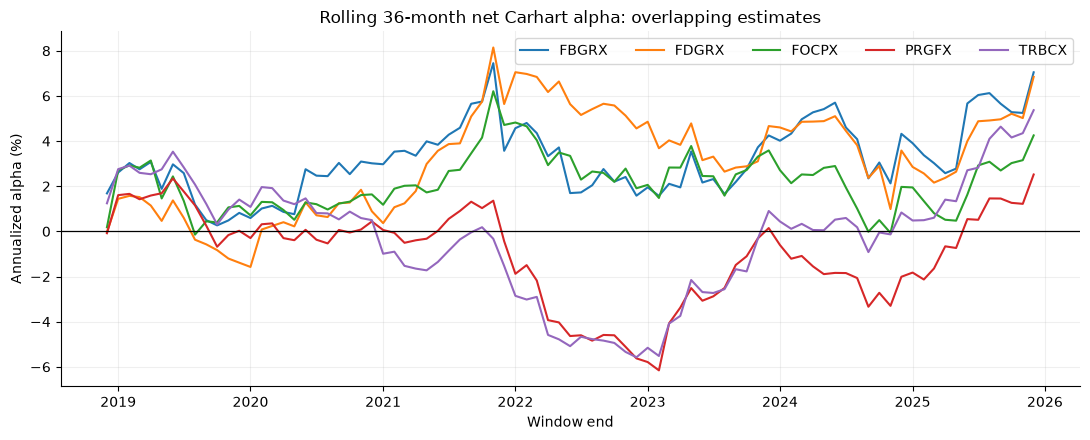

In [17]:
rolling=pd.DataFrame(index=MONTHS[35:],columns=ACTIVE,dtype=float)
for end_pos in range(35,len(MONTHS)):
    window=MONTHS[end_pos-35:end_pos+1]
    for ticker in ACTIVE:
        rolling.loc[MONTHS[end_pos],ticker]=1200*fit_factor(excess.loc[window,ticker],MODELS['Carhart']).params['const']
save_table(rolling,'table_rolling_36m_alpha',show=False)
fig,ax=plt.subplots()
for ticker in ACTIVE:ax.plot(rolling.index.to_timestamp(),rolling[ticker],label=ticker)
ax.axhline(0,color='black',lw=.9)
ax.set(title='Rolling 36-month net Carhart alpha: overlapping estimates',ylabel='Annualized alpha (%)',xlabel='Window end')
ax.legend(ncol=5)
save_figure(fig,'fig_rolling_alpha')

**What this does:** shows how the estimated net value added changes over time using strictly trailing windows, with the short-window and overlap limitations stated.

## 11. Answer, fund-by-fund fee verdicts and fee design

The final table is the report's central comparison. It places each expense next to gross and net Carhart alpha and investable-benchmark alpha. Benchmark-relative alpha is model-dependent. A historical positive estimate does not establish future performance, and a negative estimate with a wide interval calls for caution rather than certainty. The sample and data limitations are part of the answer.

In [18]:
verdict=fee_alpha.join(index_results[['index_alpha_ann_pct','benchmark_fee_ann_pct','R2']].rename(columns={'R2':'index_R2'}))
verdict['CAPM_alpha_ann_pct']=alpha_by_model.CAPM
verdict['FF3_alpha_ann_pct']=alpha_by_model.FF3
verdict['Carhart_BH_q']=carhart.BH_q_value
verdict['any_factor_benchmark_sign_change']=(alpha_by_model.ge(0).nunique(axis=1)>1)
verdict['any_sensitivity_verdict_change']=sensitivity_table.reset_index().groupby('ticker').verdict_changes.any()
save_table(verdict,'table_final_fee_verdict')
positive_counts=combined_alpha.ge(0).sum()
display(Markdown('**Research answer from this sample.** The number of funds with non-negative estimated net alpha is '
    + ', '.join(f'**{int(positive_counts[m])}/5 under {m}**' for m in combined_alpha.columns)
    + '. These are historical point-estimate verdicts; the confidence intervals and benchmark fit determine how much weight to place on them.'))
for ticker,row in verdict.iterrows():
    changes=sensitivity_table.reset_index().query('ticker == @ticker and verdict_changes')['case'].tolist()
    display(Markdown(f'**{ticker}: {row.point_fee_verdict} under the main Carhart model.** '
        f'Mean expense {row.mean_fee_ann_pct:.2f}% per year; gross alpha {row.Carhart_gross_alpha_ann_pct:.2f}%, '
        f'net alpha {row.Carhart_net_alpha_ann_pct:.2f}% (95% interval {row.net_CI_low_pct:.2f}% to {row.net_CI_high_pct:.2f}%). '
        f'{row.statistical_evidence}. Alpha against the constrained index portfolio is {row.index_alpha_ann_pct:.2f}% '
        f'and its weighted expense is {row.benchmark_fee_ann_pct:.3f}% (R² {row.index_R2:.3f}). '
        + ('The sign-based Carhart verdict changes under: '+', '.join(changes)+'.' if changes else
           'The sign-based Carhart verdict is unchanged in the displayed sensitivity cases.')))

summary={'question':"Does an active mutual fund's fee remain justified when performance is evaluated against progressively more demanding benchmarks?",
    'sample':'2016-01 to 2025-12','funds':ACTIVE,
    'nonnegative_alpha_counts':{k:int(v) for k,v in positive_counts.items()},
    'persistence_rank_correlation':rank_rho,
    'exact_monthly_class_TNA_flows_available':False,
    'reported_monthly_series_flow_funds':flow_regressions.index.tolist()}
(OUT/'results_summary.json').write_text(json.dumps(summary,indent=2)+'\n')

,mean_fee_ann_pct,Carhart_gross_alpha_ann_pct,Carhart_net_alpha_ann_pct,net_CI_low_pct,net_CI_high_pct,point_fee_verdict,statistical_evidence,index_alpha_ann_pct,benchmark_fee_ann_pct,index_R2,CAPM_alpha_ann_pct,FF3_alpha_ann_pct,Carhart_BH_q,any_factor_benchmark_sign_change,any_sensitivity_verdict_change
ticker,,,,,,,,,,,,,,,
FBGRX,0.7088,3.5526,2.8414,-0.7709,6.4538,Appears justified,Inconclusive at 95%,2.2146,0.0510,0.9460,2.7093,2.7453,0.2576,False,False
FDGRX,0.7693,4.3751,3.6032,-0.0174,7.2238,Appears justified,Inconclusive at 95%,3.3901,0.0510,0.9328,3.5679,3.7701,0.2555,False,False
FOCPX,0.8160,3.4235,2.6066,-0.9965,6.2097,Appears justified,Inconclusive at 95%,1.3973,0.0510,0.9313,3.0300,2.5649,0.2576,False,True
PRGFX,0.6560,-0.6250,-1.2815,-4.7495,2.1865,Not covered by estimated alpha,Inconclusive at 95%,-2.7527,0.0510,0.9603,-0.8932,-1.3817,0.5821,False,True
TRBCX,0.6980,0.4109,-0.2875,-3.7838,3.2087,Not covered by estimated alpha,Inconclusive at 95%,-1.4909,0.0510,0.9576,0.5664,-0.3456,0.8709,True,True


**Research answer from this sample.** The number of funds with non-negative estimated net alpha is **4/5 under CAPM**, **3/5 under FF3**, **3/5 under Carhart**, **3/5 under Index funds**. These are historical point-estimate verdicts; the confidence intervals and benchmark fit determine how much weight to place on them.

**FBGRX: Appears justified under the main Carhart model.** Mean expense 0.71% per year; gross alpha 3.55%, net alpha 2.84% (95% interval -0.77% to 6.45%). Inconclusive at 95%. Alpha against the constrained index portfolio is 2.21% and its weighted expense is 0.051% (R² 0.946). The sign-based Carhart verdict is unchanged in the displayed sensitivity cases.

**FDGRX: Appears justified under the main Carhart model.** Mean expense 0.77% per year; gross alpha 4.38%, net alpha 3.60% (95% interval -0.02% to 7.22%). Inconclusive at 95%. Alpha against the constrained index portfolio is 3.39% and its weighted expense is 0.051% (R² 0.933). The sign-based Carhart verdict is unchanged in the displayed sensitivity cases.

**FOCPX: Appears justified under the main Carhart model.** Mean expense 0.82% per year; gross alpha 3.42%, net alpha 2.61% (95% interval -1.00% to 6.21%). Inconclusive at 95%. Alpha against the constrained index portfolio is 1.40% and its weighted expense is 0.051% (R² 0.931). The sign-based Carhart verdict changes under: Early sample 2016–2020.

**PRGFX: Not covered by estimated alpha under the main Carhart model.** Mean expense 0.66% per year; gross alpha -0.62%, net alpha -1.28% (95% interval -4.75% to 2.19%). Inconclusive at 95%. Alpha against the constrained index portfolio is -2.75% and its weighted expense is 0.051% (R² 0.960). The sign-based Carhart verdict changes under: Recent sample 2021–2025.

**TRBCX: Not covered by estimated alpha under the main Carhart model.** Mean expense 0.70% per year; gross alpha 0.41%, net alpha -0.29% (95% interval -3.78% to 3.21%). Inconclusive at 95%. Alpha against the constrained index portfolio is -1.49% and its weighted expense is 0.051% (R² 0.958). The sign-based Carhart verdict changes under: Recent sample 2021–2025, Winsorized 1st/99th percentiles, Baseline fees on filed-fee coverage, Latest filed expense; same paired dates.

548

**What this does:** answers the selected question using generated results, gives an explicit verdict and uncertainty for every fund, and records a machine-readable summary without hard-coded conclusions.

### 11.1 How should the audience pay for active management?

**Recommendation tied to the evidence:** use the inexpensive growth/style portfolio as the default opportunity-cost benchmark. An active mandate needs credible net value beyond it and suitable access, rather than a large raw return or a favorable CAPM intercept alone. Where the main table shows negative net alpha or unstable benchmark/sample verdicts, the historical evidence does not justify paying that expense simply to obtain the observed exposures. Where net alpha is positive, consider its interval, holdout result and persistence before interpreting the fee as payment for repeatable skill.

For investors able to negotiate a separate mandate, use a low base fee and a **symmetric performance adjustment** around an agreed risk-matched, investable benchmark, together with beta/style and tracking-error limits and a multi-year review horizon. The classroom 40-Act discussion requires symmetry for mutual-fund performance fees. A bonus that pays only for beating the raw S&P 500 can reward extra market beta or growth exposure without skill. Factor regressions monitor risk adjustment; an agreed index portfolio provides a transparent investable reference. Some sampled Fidelity funds already use performance-adjusted management fees: changing the fee structure alone does not guarantee net alpha.

For illustration only, a base fee of 0.50% with a ±10% adjustment to benchmark-relative performance gives 0.00%, 0.50%, and 1.00% fees at relative returns of −5%, 0%, and +5%. This arithmetic illustrates symmetry and is not an estimate of the sampled funds' actual contracts or an optimized contract. A flat asset fee is easy to administer but pays the manager even when investors receive no alpha. Retail investors normally choose among published share-class terms rather than negotiate them, making class selection and the low-cost alternative especially relevant. Advisory services such as planning are separate from the portfolio alpha measured here.

### 11.2 Limitations that change how to use the answer

- **Survival, incubation and selection:** five successful-to-survive public records exclude liquidated or merged funds and privately incubated failures. Inherited histories or a surviving share class can hide earlier investors' experience. Contemporary category/access flags and family concentration limit generalization. We do not call this a survivor-bias-free universe.
- **Return-source precision:** the fiscal-year validation table contains residual differences between Yahoo-derived returns and financial-highlight returns; the exception table identifies those above 10 basis points. All source values are retained. Calendar-year pilot agreement for FBGRX/TRBCX did not guarantee exact fiscal-year agreement for the full universe. The adjusted-close sensitivity assesses one alternative, but both methods share Yahoo source risks.
- **Expense approximation:** realized fiscal average expenses are spread evenly over months, and FDGRX December 2025 uses its last completed fiscal rate. The gross series remains after trading costs, and excludes investor taxes, loads, account charges and external advisory costs. Use the documented selected classes, rather than assume a fund name identifies one universal fee.
- **Benchmark choice:** four factors do not span every growth/technology, quality, profitability or foreign exposure. The convex index portfolio is constrained, whereas CAPM/FF3/Carhart allow long–short and levered exposures. Differences in intercepts do not measure a universal quantity of skill. Full-sample style weights use hindsight; the frozen holdout check is stricter but can become stale.
- **Precision and sample:** ten years, five funds and two families offer limited power. HAC estimates and multiple-test adjustments do not remove selection, omitted exposures or structural changes. Crisis months remain in the baseline; rolling windows overlap.
- **Flows:** exact monthly class TNA flows could not be computed. Annual residual flows contain timing/transfer effects; observed monthly N-PORT flows are series-level for two funds and are scaled by prior-quarter TNA. Their association with retail-class past returns is descriptive and does not identify capacity effects. The original monthly-TNA part of requirement 9 remains a disclosed data limitation.
- **Fee distribution:** ICI's broad US-registered equity and growth universes differ from five domestic-oriented large-growth case studies. Only bands relative to published quantiles are identified. Asset-weighted means describe dollars invested, while median/quantiles weight classes equally.

The lecturer's historical Wermers, Fama–French and Carhart findings motivate the exercise; our estimates are new case-study results rather than attempted numerical matches to those different samples.

## 12. Consistency checks, sources and submission checklist
### 12.1 Arithmetic, calendar and reproducibility checks

These assertions target economically consequential errors: double-counted distributions, split handling, annualization, factor units, mismatched samples, constraint violations, annual-to-monthly asset gaps and inadvertent use of future performance in flow predictors. They do not force estimates to match a lecture or assume active funds must fail.

In [19]:
assert net.index.equals(MONTHS) and net.shape==(120,5)
assert factors.index.equals(MONTHS) and index_returns.index.equals(MONTHS)
assert net.notna().all().all() and fees.notna().all().all()
assert np.allclose(gross-net,fees/12)
assert np.allclose(excess,net.sub(factors.RF,axis=0))
assert np.allclose(contributions.sum_ann_pct,contributions.mean_excess_ann_pct,atol=1e-9)
assert (weights.min(axis=1)>=-1e-9).all() and np.allclose(weights.sum(axis=1),1)
for ticker in ACTIVE:
    for model,cols in MODELS.items():
        fit=models[ticker,model]
        assert fit.nobs==120 and fit.model.data.row_labels.equals(MONTHS)
        row=factor_results.loc[ticker,model]
        assert np.isclose(row.alpha_ann_pct/row.TE_ann_pct,row.IR_ann)
        assert np.isclose(row.TE_ann_pct,np.std(fit.resid,ddof=1)*100*np.sqrt(12))
    f=index_fits[ticker];w=f['weights']
    assert np.isclose(f['alpha'],(net[ticker]-index_returns@w).mean())
    best_single=min(np.mean(((net[ticker]-net[ticker].mean())-(index_returns[j]-index_returns[j].mean()))**2)*10000 for j in INDEX)
    assert f['objective']<=best_single+1e-8
assert flow_availability.consecutive_monthly_class_TNA_pairs.sum()==0
assert np.allclose(annual_flow.inferred_flow_usd,
    annual_flow.TNA_usd-annual_flow.prior_TNA_usd*(1+annual_flow.period_return))
assert np.allclose(reported_flow.net_external_flow_usd,reported_flow.sales_usd-reported_flow.redemptions_usd.abs())
assert np.allclose(sensitivity_table.loc['Baseline fees on filed-fee coverage','net_alpha_ann_pct'],
    sensitivity_table.loc['Latest filed expense; same paired dates','net_alpha_ann_pct'])
assert (reported_flow.quarter_end-reported_flow.prior_quarter_end).map(lambda x:x.n).eq(3).all()
assert (rolling.index==MONTHS[35:]).all() and rolling.notna().all().all()
assert len(sensitivity_table.index.get_level_values('case').unique())>=3
assert all((DATA/name).is_file() and hashlib.sha256((DATA/name).read_bytes()).hexdigest()==spec['sha256']
           for name,spec in sources['files'].items())
print('All return, units, sample, constraint, flow-frequency and source-integrity checks passed.')
print('Exact monthly class TNA flow requirement: unavailable; supported alternatives are explicitly labeled in Section 9.')
print('Tables and figures saved in output/. No input file was changed or fetched.')

All return, units, sample, constraint, flow-frequency and source-integrity checks passed.
Exact monthly class TNA flow requirement: unavailable; supported alternatives are explicitly labeled in Section 9.
Tables and figures saved in output/. No input file was changed or fetched.


**What this does:** verifies the numerical identities and portfolio constraints, prevents unsupported monthly flows, checks source-file hashes, and confirms the offline run uses only included inputs.

### 12.2 Sources and interpretation notes

1. **Course assignment:** *CFM301_Project5_Mutual_Fund_Fees_v2.pdf*, requirements 1–12 and rubric. User supplied the instructor's later clarification that paid data are not expected and limitations must be disclosed. That clarification is recorded in `data/sources.json`.
2. **Chapter 10, Alpha (and the Low-Risk Anomaly):** slides 17–18 distinguish regression tracking error; slides 28–29 specify annualization; slides 31–34 motivate constrained index-fund benchmarks; slides 36–40 motivate added factors. Our convex four-index benchmark includes a growth fund suitable for this sample, and need not reproduce Berkshire's exposures or alpha.
3. **Chapter 16, Mutual Funds and Other 40-Act Funds:** slides 20–23 motivate gross/net alpha, expense/turnover relationships and persistence; slide 26 motivates flow-performance analysis; slides 32–33 explain Berk and Green. Slides 17–19 and 29–30 motivate survivorship/incubation caveats; slide 11 covers symmetric fee design in the classroom framework.
4. **Chapter 15, Delegated Investing:** slides 23–28 explain why raw-index outperformance can reward beta rather than skill, and slides 15–16 explain symmetric contracts. The fee comparison referenced as slide 36 by the assignment is actually slide **38** in the attached version. The lecture's fee averages are not used as a substitute for dated fund expenses.
5. **Yahoo Finance:** daily chart data from `query1.finance.yahoo.com/v8/finance/chart/{ticker}`, downloaded November 20, 2026. Dates and fields are in `sources.json`. [Example fund history](https://finance.yahoo.com/quote/FBGRX/history/). Raw distributions and split-event metadata are included; adjusted-close and reconstructed returns are compared empirically.
6. **SEC/fund-company financial highlights:** see `financial_highlights_sources.json` for exact URLs, table text, class headings and filing dates. Original percentage strings and asset multipliers remain in the raw CSV. [Example Fidelity archival report](https://www.sec.gov/Archives/edgar/data/754510/000137949119004148/filing989.htm), [example T. Rowe Price prospectus](https://www.sec.gov/Archives/edgar/data/902259/000199937126004097/bcg-485bpos_022526.htm), [example Vanguard prospectus](https://www.sec.gov/Archives/edgar/data/36405/000003640526000181/f45032d1.htm). Fund/class IDs were matched against the [SEC mutual fund ticker file](https://www.sec.gov/files/company_tickers_mf.json).
7. **French factors:** [Ken French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html), US 3-factor and momentum monthly files, both identified as September 2026 vintage. Monthly percentages are preserved in the input CSV and converted once. The legacy Project Two factor file is not mixed with this vintage.
8. **ICI:** Lei Li (2026), *Trends in the Expenses and Fees of Funds, 2025*, ICI Research Perspective 32(1), Figure 2, printed page 2. [Report](https://www.ici.org/system/files/2026-03/per32-01.pdf). The two relevant rows are transcribed into a cited CSV; published quantiles describe share classes, not assets.
9. **SEC N-PORT:** [dataset documentation](https://www.sec.gov/data-research/sec-markets-data/form-n-port-data-sets). Individual filing URLs are retained on every source row. Quarterly filings provide monthly return and flow fields for the preceding three months, while the balance sheet is at the quarter end. Sales minus the absolute redemption withdrawal amount excludes reinvestments; the raw signed convention changes in 2024 and is normalized explicitly. The code does not invent the missing intervening class assets.
10. **Methods/software:** numpy/pandas for arithmetic, scipy SLSQP for the convex benchmark and statistical functions, statsmodels OLS/HAC and multiple-testing adjustments, matplotlib for figures, Jupyter/IPython for execution. Versions are printed in Section 2 and pinned in `requirements.txt`. The financial-highlight raw extraction and source acquisition are documented by the included preparation script; the analysis itself is fully contained in this notebook.

### 12.3 Requirements and remaining course deliverables

| Requirement | Notebook evidence | Status |
|---|---|---|
| 1. Question and audience | Sections 1 and 11 | Addressed |
| 2. Five funds, returns and expenses | Sections 1–3; source/class identifiers | Addressed |
| 3. Distributions, classes, excess returns, fee frequency | Sections 3–4 | Addressed; expense add-back approximation flagged |
| 4. Missing values, duplicates, outliers, affected counts | Section 3 and cleaning log | Addressed |
| 5. Three models and all five performance metrics | Section 5 | Addressed |
| 6. Gross and net alpha | Section 6, all three models | Addressed |
| 7. Non-negative fully invested index benchmark and costs | Section 7 | Addressed; holdout and fit checks added |
| 8. Fee/turnover relationship and equity fee distribution | Section 8 | Addressed descriptively with published quantile bands |
| 9. Persistence, flows, Berk and Green | Section 9 | Persistence addressed; monthly class TNA formula unavailable. Annual class estimates and actual monthly series flows supplied as disclosed alternatives |
| 10. At least two assumptions and fee-verdict changes | Section 10 | Addressed: sample and winsorization, plus additional checks |
| 11. Every fund's fee verdict and caveats | Section 11 | Addressed |
| 12. Fee design connected to evidence and theory | Section 11.1 | Addressed |
| Reproducibility | Local data, relative paths, versions, assertions, README | Clean-start execution checked during preparation |

This notebook supplies the analysis and code. The group still needs the **maximum-four-page report**, **5–6 minute slides/presentation**, attendance and individual preparation, a substantive paired-group peer-review question, and a clean-folder run by a member who did not write the code. A developer's execution cannot substitute for that last group-member check. Report/code/data/README are due two days before the presentation; slides one hour before the session, as stated in the assignment. No presentation date was supplied, so no calendar deadline is invented.

For the report, use `table_factor_regressions.csv`, `table_final_fee_verdict.csv`, `table_persistence.csv`, the compact flow summaries, and `table_sensitivity.csv`; include the requirement-9 limitation beside the flow evidence. The notebook is the source of every numeric table and figure. Source facts and teaching examples are labeled separately from estimated results.